In [10]:
import re
import statistics
from collections import Counter, defaultdict
import textwrap

pd = None  # not used — everything is done with the standard library only


# ==============================================================================
# 1. LIKERT SCALE ENCODING (used for questionnaire items 6–23)
# ==============================================================================
LIKERT_MAP = {
    "Strongly Disagree": 1,
    "Disagree": 2,
    "Not Sure": 3,
    "Agree": 4,
    "Strongly Agree": 5,
}

# Deductive grouping of the 18 Likert items into the constructs used in the
# conceptual framework (Section 2.9): engagement -> communicative behaviour
# -> perceptions of ELAA / feasibility
ENGAGEMENT_ITEMS = {
    "q6": "I pay attention during English lessons.",
    "q7": "I enjoy taking part in English classroom activities.",
    "q8": "I feel motivated to speak English in class.",
    "q9": "I work actively with my classmates during English activities.",
    "q10": "I feel confident when I use English in classroom tasks.",
    "q11": "I try to complete English tasks even when they are difficult.",
}
COMMUNICATIVE_BEHAVIOUR_ITEMS = {
    "q12": "I speak more English during activity-based lessons.",
    "q13": "I ask questions in English during classroom activities.",
    "q14": "I respond to my classmates in English during group work.",
    "q15": "I use English to share ideas, not only to answer the teacher.",
    "q16": "I try to continue communication even when I do not know some words.",
}
PERCEPTION_ITEMS = {
    "q17": "Classroom activities help me improve my speaking ability.",
    "q18": "Group discussions/role-plays make English lessons more engaging.",
    "q19": "ELAA activities help me use English in real situations.",
    "q20": "I prefer ELAA activities to traditional teacher-led lessons.",
    "q21": "ELAA activities help me communicate with classmates in English.",
    "q22": "ELAA activities reduce my fear of speaking English in class.",
    "q23": "I would like my teacher to include more activity-based tasks.",
}
ALL_LIKERT_ITEMS = {**ENGAGEMENT_ITEMS, **COMMUNICATIVE_BEHAVIOUR_ITEMS, **PERCEPTION_ITEMS}


# ==============================================================================
# 2. EMBEDDED STUDENT QUESTIONNAIRE DATA (20 respondents)
# ==============================================================================
STUDENTS = [
    dict(id=1, total=79, age=18, gender="Female", level="Intermediate",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree",
         q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree",
         comment="I love fun group games and interactive tasks, which let me use words freely without heavy memorization pressure."),

    dict(id=2, total=64, age=18, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Not Sure", q14="Disagree", q15="Disagree", q16="Not Sure",
         q17="Not Sure", q18="Agree", q19="Agree", q20="Not Sure", q21="Agree", q22="Not Sure", q23="Not Sure",
         comment="I can have the real chance to use English."),

    dict(id=3, total=68, age=18, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree",
         comment="I loved that these activities focused on real-life language application instead of rigid textbook memorization. We got to interact, discuss topics and practice speaking freely without much pressure."),

    dict(id=4, total=61, age=17, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Agree", q10="Disagree", q11="Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Not Sure", q16="Disagree",
         q17="Strongly Agree", q18="Not Sure", q19="Agree", q20="Agree", q21="Not Sure", q22="Agree", q23="Not Sure",
         comment="They combine real-life communication with language learning instead of rigid textbook drills. I no longer feel nervous about opening my mouth in English."),

    dict(id=5, total=82, age=18, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Agree",
         comment="It helps speak more."),

    dict(id=6, total=54, age=18, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Not Sure", q18="Not Sure", q19="Not Sure", q20="Not Sure", q21="Not Sure", q22="Not Sure", q23="Not Sure",
         comment="The activities were highly interactive and practical. I also enjoyed working in groups because it gave me more opportunities to practice speaking without feeling too pressured."),

    dict(id=7, total=65, age=17, gender="Male", level="Low",
         q6="Agree", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Not Sure", q23="Agree",
         comment="reading"),

    dict(id=8, total=86, age=18, gender="Male", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Not Sure", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree",
         comment="I love the interactive group tasks most. It greatly improves my willingness to speak English bravely."),

    dict(id=9, total=78, age=17, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Strongly Agree", q11="Not Sure",
         q12="Strongly Agree", q13="Agree", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Not Sure", q21="Strongly Agree", q22="Strongly Agree", q23="Agree",
         comment="The ELAA framework perfectly balanced fun and practicality without making learners feel pressured."),

    dict(id=10, total=73, age=17, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Agree", q13="Agree", q14="Strongly Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Strongly Agree", q19="Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree",
         comment="The interesting and various activities which can help me learn and use English better."),

    dict(id=11, total=81, age=18, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Not Sure", q9="Agree", q10="Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Strongly Agree",
         comment="I love the group discussion parts most. We can freely share ideas with classmates instead of just listening to teachers."),

    dict(id=12, total=90, age=18, gender="Male", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree",
         comment="I love the group discussions. They let me practice English freely with classmates."),

    dict(id=13, total=62, age=18, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Not Sure", q20="Agree", q21="Agree", q22="Agree", q23="Agree",
         comment="My favorite ELAA-based activities are role-play conversations and free group discussions."),

    dict(id=14, total=90, age=17, gender="Female", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree",
         comment="Role-play, group discussion, English debate, English speech, and situational teaching used in class."),

    dict(id=15, total=75, age=18, gender="Male", level="Low",
         q6="Agree", q7="Strongly Agree", q8="Not Sure", q9="Strongly Agree", q10="Agree", q11="Agree",
         q12="Strongly Agree", q13="Not Sure", q14="Agree", q15="Not Sure", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree",
         comment="ELAA replaces boring traditional textbook teaching with lots of interactive practice. I can practice my oral English naturally without pressure."),

    dict(id=16, total=80, age=18, gender="Male", level="High",
         q6="Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Agree", q10="Not Sure", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Disagree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Disagree", q22="Strongly Agree", q23="Strongly Agree",
         comment="Some task based activities, group discussions, games, debates."),

    dict(id=17, total=70, age=18, gender="Male", level="Low",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree",
         comment="Role-play"),

    dict(id=18, total=64, age=18, gender="Male", level="Intermediate",
         q6="Disagree", q7="Agree", q8="Disagree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree",
         comment="I like group discussions and role-play."),

    dict(id=19, total=74, age=17, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree",
         comment="I like the situational approach in English teaching."),

    dict(id=20, total=73, age=18, gender="Female", level="Low",
         q6="Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Not Sure", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree",
         comment="I liked the group discussions best. We could freely share our ideas with partners, which made learning fun and relaxing."),
]


# ==============================================================================
# 3. EMBEDDED TEACHER INTERVIEW DATA (English responses, by section)
#    Kept as (question, answer) pairs for deductive + inductive coding.
# ==============================================================================
TEACHER_INTERVIEW = {
    "A. Teacher Background": [
        ("How long have you been teaching English?",
         "I have been teaching English for about one year. I am still a relatively new teacher, so I am continuing to develop my classroom management and teaching skills."),
        ("What grade or level do you currently teach?",
         "I currently teach Grade 10 students in a senior high school, which is the first year of high school in China."),
        ("Have you used activity-based or communicative teaching methods before?",
         "No, I had not used activity-based or communicative teaching methods before this study. Teachers often focus more on examination results, grammar, vocabulary, and reading skills because students are under pressure to achieve high scores, so I mainly used traditional teacher-centred methods before."),
    ],
    "B. Implementation of ELAA": [
        ("How did you understand the purpose of ELAA before the study?",
         "I understood ELAA as a teaching approach that encourages students to learn English through meaningful activities and communication rather than only through explanation and memorisation, to increase participation and provide opportunities to use English in real situations."),
        ("How easy or difficult was it to include ELAA-based activities in your normal lessons?",
         "It was somewhat difficult at the beginning because I was not familiar with this teaching approach. I also needed to consider the teaching schedule and exam preparation. After several lessons, I became more comfortable organising activities and giving instructions."),
        ("What types of ELAA activities worked best in your classroom?",
         "Pair discussions, group discussions, and short role-play activities worked best. These activities allowed students to share ideas with classmates and practise speaking in a less stressful environment."),
        ("Were there any activities that did not work well? Why?",
         "Some longer speaking tasks did not work very well. A few students were not confident enough to speak English for an extended period, and some groups became off-task. Time management was also a challenge."),
    ],
    "C. Learner Engagement": [
        ("How did students respond to ELAA-based activities?",
         "Most students responded positively. They seemed more active than in traditional lessons, especially when they could work with their classmates."),
        ("Did you notice any changes in student participation?",
         "Yes. More students were willing to answer questions and participate in discussions. In traditional lessons the same students usually spoke, but during ELAA activities some quieter students also contributed."),
        ("Did students appear more motivated or interested during the ELAA lessons?",
         "Yes, many students appeared more interested because the lessons were more interactive. They enjoyed exchanging opinions and completing tasks together."),
        ("Were there any students who remained passive or uncomfortable? Why?",
         "Yes, a small number of students remained passive. I think this was mainly because of limited speaking ability, lack of confidence, and fear of making mistakes in front of classmates."),
    ],
    "D. Communicative Behaviour": [
        ("How did students use English differently during ELAA activities compared to traditional lessons?",
         "During ELAA activities students used English more actively to express opinions, ask questions, and respond to classmates. In traditional lessons they mainly answered the teacher's questions with short, fixed responses."),
        ("How did students interact with their classmates?",
         "Students interacted more frequently with their classmates. I noticed turn-taking, asking for clarification, agreeing and disagreeing, and helping each other find words or expressions."),
        ("What changes did you notice in students' confidence when speaking English?",
         "Some students became more confident after participating in several activities. For example, one student who was usually very quiet volunteered to report the group's ideas to the whole class."),
        ("What kinds of communicative behaviours did you observe?",
         "I observed students asking questions, responding to peers, giving opinions, explaining their ideas, and sometimes negotiating meaning when they did not understand each other clearly."),
    ],
    "E. Challenges and Limitations": [
        ("What challenges did you face when using ELAA?",
         "The main challenges were classroom management, controlling noise levels, and ensuring that students used English rather than Chinese during activities."),
        ("Did class size, time limits, exam pressure, or curriculum requirements affect the use of ELAA?",
         "Yes, all of these factors affected the use of ELAA. Exam pressure is very strong in China, and teachers need to prepare students for tests, so it is sometimes difficult to spend a large amount of class time on communicative activities."),
        ("Was it difficult to manage students during activity-based lessons?",
         "At first, yes, because I had only one year of teaching experience and my classroom management skills were still developing. Some students became too excited during group work, but I gradually learned to set clearer rules and time limits."),
        ("What support would teachers need to use ELAA more effectively?",
         "Teachers would need training on how to design communicative tasks, manage group activities, and assess students' performance. More teaching resources and examples of successful ELAA lessons would also be helpful."),
    ],
    "F. Overall Evaluation": [
        ("Is ELAA useful for improving learner engagement?",
         "Yes, ELAA is useful for improving learner engagement because students have more chances to participate actively and cooperate with classmates. The classroom atmosphere becomes more lively and student-centred."),
        ("Is ELAA useful for improving students' communicative competence?",
         "Yes, ELAA can help improve students' communicative competence. Students practise expressing ideas, listening to others, and responding in English, skills not fully developed through traditional grammar-focused teaching."),
        ("How does ELAA compare with more traditional English teaching methods?",
         "ELAA is more interactive and student-centred, while traditional methods are usually more teacher-centred and focused on knowledge explanation and exam preparation. Traditional teaching may be more efficient for grammar and test-taking skills, but ELAA provides more opportunities for real communication."),
        ("Would you continue using ELAA in future lessons?",
         "Yes, I would like to continue using some ELAA activities in future lessons. However I would probably combine them with traditional teaching methods to balance communicative practice with exam preparation."),
        ("Is there anything else you would like to add about your experience using ELAA?",
         "As a new teacher, this was my first experience using a communicative and activity-based approach. It was challenging but also valuable. Students can be more engaged and willing to communicate when given meaningful tasks. In future I hope to learn more about adapting ELAA to the Chinese high school context while still meeting examination requirements."),
    ],
}


# ==============================================================================
# 4. DEDUCTIVE + INDUCTIVE CODING SCHEME (Section 3.7)
#    Deductive codes come from the research questions (engagement,
#    communicative behaviour, feasibility). Inductive codes emerge from the
#    data itself (anxiety, exam pressure, peer support, classroom management,
#    time pressure, teacher scaffolding/confidence).
# ==============================================================================
THEME_KEYWORDS = {
    # --- Deductive themes (tied directly to the research questions) ---
    "Engagement (deductive)": [
        "active", "engag", "motivat", "interest", "particip", "responded positively",
        "enjoy", "willing", "contribut", "lively"
    ],
    "Communicative behaviour (deductive)": [
        "ask questions", "respond", "turn-taking", "clarification", "negotiat",
        "express", "opinions", "interact", "communicat", "speak", "explain"
    ],
    "Feasibility / implementation (deductive)": [
        "difficult", "challenge", "manage", "schedule", "exam preparation",
        "curriculum", "training", "resources", "time management"
    ],
    # --- Inductive themes (emerging directly from the interview content) ---
    "Confidence / anxiety (inductive)": [
        "confiden", "afraid", "fear", "nervous", "anxious", "shy", "quiet",
        "not confident", "mistakes"
    ],
    "Exam pressure (inductive)": [
        "exam", "test", "score", "curriculum", "pressure"
    ],
    "Peer support / collaboration (inductive)": [
        "classmates", "group", "pair", "cooperat", "each other", "peer"
    ],
    "Classroom management (inductive)": [
        "noise", "off-task", "rules", "time limit", "discipline", "excited",
        "control"
    ],
    "Teacher scaffolding / novice-teacher confidence (inductive)": [
        "new teacher", "one year", "developing", "not familiar", "comfortable",
        "experience"
    ],
}

# Student open-ended comment (Q24) inductive theme keywords
STUDENT_COMMENT_THEMES = {
    "Enjoyment / fun": ["fun", "love", "enjoy", "relax", "lively"],
    "Reduced pressure / anxiety": ["pressure", "nervous", "without pressure", "freely", "afraid"],
    "Real-life / practical use": ["real-life", "real situations", "practical", "naturally", "in daily"],
    "Group discussion / role-play preference": ["group discussion", "role-play", "role play", "debate", "situational"],
    "Speaking confidence / willingness": ["confidence", "willing", "bravely", "speak"],
    "Off-topic / minimal response": ["reading"],
}


def code_text(text, keyword_dict):
    """Return a Counter of theme -> number of keyword hits found in text."""
    text_lower = text.lower()
    hits = Counter()
    for theme, keywords in keyword_dict.items():
        for kw in keywords:
            if kw.lower() in text_lower:
                hits[theme] += 1
    return hits


# ==============================================================================
# 5. QUANTITATIVE ANALYSIS (Section 3.7 — descriptive statistics only,
#    no inferential testing, consistent with the small-sample rationale)
# ==============================================================================
def numeric(item_code, student):
    return LIKERT_MAP[student[item_code]]


def describe_item(item_code, label):
    values = [numeric(item_code, s) for s in STUDENTS]
    dist = Counter(s[item_code] for s in STUDENTS)
    n = len(values)
    agree_pct = 100 * (dist["Agree"] + dist["Strongly Agree"]) / n
    disagree_pct = 100 * (dist["Disagree"] + dist["Strongly Disagree"]) / n
    print(f"  {item_code.upper()}: {label}")
    print(f"    Mean = {statistics.mean(values):.2f}  |  SD = {statistics.pstdev(values):.2f}  "
          f"|  Agree/Strongly Agree = {agree_pct:.0f}%  |  Disagree/Strongly Disagree = {disagree_pct:.0f}%")
    order = ["Strongly Disagree", "Disagree", "Not Sure", "Agree", "Strongly Agree"]
    freq_str = ", ".join(f"{k}={dist.get(k, 0)}" for k in order)
    print(f"    Frequencies: {freq_str}")


def composite_score(student, item_dict):
    return statistics.mean(numeric(code, student) for code in item_dict)


def run_quantitative_analysis():
    print("\n" + "=" * 78)
    print("SECTION 3.7 (QUANTITATIVE): DESCRIPTIVE STATISTICS — STUDENT QUESTIONNAIRE")
    print("=" * 78)
    print(f"\nSample size (n) = {len(STUDENTS)}")
    print("Note: descriptive statistics only are reported, consistent with the")
    print("methodology's decision not to use inferential testing on a small sample.\n")

    print("-" * 78)
    print("A) ITEM-LEVEL DESCRIPTIVES BY CONSTRUCT")
    print("-" * 78)

    for construct_name, item_dict in [
        ("ENGAGEMENT ITEMS (Q6-Q11)", ENGAGEMENT_ITEMS),
        ("COMMUNICATIVE BEHAVIOUR ITEMS (Q12-Q16)", COMMUNICATIVE_BEHAVIOUR_ITEMS),
        ("PERCEPTION / FEASIBILITY ITEMS (Q17-Q23)", PERCEPTION_ITEMS),
    ]:
        print(f"\n{construct_name}")
        for code, label in item_dict.items():
            describe_item(code, label)

    print("\n" + "-" * 78)
    print("B) COMPOSITE CONSTRUCT SCORES PER STUDENT (mean of items, 1-5 scale)")
    print("-" * 78)
    engagement_scores, comm_scores, perception_scores = [], [], []
    print(f"{'ID':<4}{'Gender':<8}{'Level':<13}{'Engagement':<12}{'Comm.Behav.':<13}{'Perception':<11}{'Overall Total'}")
    for s in STUDENTS:
        e = composite_score(s, ENGAGEMENT_ITEMS)
        c = composite_score(s, COMMUNICATIVE_BEHAVIOUR_ITEMS)
        p = composite_score(s, PERCEPTION_ITEMS)
        engagement_scores.append(e)
        comm_scores.append(c)
        perception_scores.append(p)
        print(f"{s['id']:<4}{s['gender']:<8}{s['level']:<13}{e:<12.2f}{c:<13.2f}{p:<11.2f}{s['total']}")

    print("\nConstruct-level summary (mean across all 20 students):")
    print(f"  Engagement composite mean            = {statistics.mean(engagement_scores):.2f} "
          f"(SD = {statistics.pstdev(engagement_scores):.2f})")
    print(f"  Communicative behaviour composite mean = {statistics.mean(comm_scores):.2f} "
          f"(SD = {statistics.pstdev(comm_scores):.2f})")
    print(f"  Student Perceptions of ELAA composite mean  = {statistics.mean(perception_scores):.2f} "
          f"(SD = {statistics.pstdev(perception_scores):.2f})")

    print("\n" + "-" * 78)
    print("C) DESCRIPTIVE BREAKDOWN BY GENDER AND SELF-RATED SPEAKING LEVEL")
    print("   (descriptive comparison only — no significance testing, per 3.7)")
    print("-" * 78)

    def group_summary(group_key):
        groups = defaultdict(list)
        for s in STUDENTS:
            groups[s[group_key]].append(composite_score(s, ALL_LIKERT_ITEMS))
        for g, vals in sorted(groups.items()):
            print(f"  {group_key.capitalize()} = {g:<13} n={len(vals):<3} "
                  f"Mean overall Likert score = {statistics.mean(vals):.2f}")

    print("\nBy gender:")
    group_summary("gender")
    print("\nBy self-rated speaking level:")
    group_summary("level")

    return engagement_scores, comm_scores, perception_scores


# ==============================================================================
# 6. QUALITATIVE ANALYSIS — TEACHER INTERVIEW (deductive + inductive coding)
# ==============================================================================
def run_teacher_interview_analysis():
    print("\n" + "=" * 78)
    print("SECTION 3.7 (QUALITATIVE): THEMATIC ANALYSIS — TEACHER INTERVIEW")
    print("=" * 78)
    print("\nDeductive codes = drawn from the research questions (engagement,")
    print("communicative behaviour, feasibility). Inductive codes = emerged from")
    print("the interview content itself (confidence/anxiety, exam pressure, peer")
    print("support, classroom management, novice-teacher scaffolding needs).\n")

    overall_hits = Counter()
    theme_quotes = defaultdict(list)

    for section, qa_list in TEACHER_INTERVIEW.items():
        for question, answer in qa_list:
            hits = code_text(answer, THEME_KEYWORDS)
            overall_hits.update(hits)
            for theme in hits:
                theme_quotes[theme].append((section, question, answer))

    print("-" * 78)
    print("A) THEME FREQUENCY ACROSS ALL 21 INTERVIEW ANSWERS")
    print("-" * 78)
    for theme, count in overall_hits.most_common():
        print(f"  {theme:<55} keyword hits = {count}")

    print("\n" + "-" * 78)
    print("B) ILLUSTRATIVE EXCERPTS PER THEME (max 2 per theme, paraphrased context)")
    print("-" * 78)
    for theme, entries in theme_quotes.items():
        print(f"\n  THEME: {theme}")
        for section, question, answer in entries[:2]:
            wrapped = textwrap.fill(answer, width=74, initial_indent="      ", subsequent_indent="      ")
            print(f"    [{section}] Q: {question}")
            print(wrapped)

    return overall_hits


# ==============================================================================
# 7. QUALITATIVE ANALYSIS — OPEN-ENDED STUDENT COMMENTS (Q24, inductive)
# ==============================================================================
def run_student_comment_analysis():
    print("\n" + "=" * 78)
    print("SECTION 3.7 (QUALITATIVE): THEMATIC ANALYSIS — OPEN-ENDED STUDENT COMMENTS (Q24)")
    print("=" * 78)

    overall_hits = Counter()
    theme_examples = defaultdict(list)

    for s in STUDENTS:
        hits = code_text(s["comment"], STUDENT_COMMENT_THEMES)
        overall_hits.update(hits)
        for theme in hits:
            theme_examples[theme].append((s["id"], s["comment"]))

    print("\nTheme frequency across 20 open-ended responses:")
    for theme, count in overall_hits.most_common():
        n_students = len(theme_examples[theme])
        print(f"  {theme:<38} mentions = {count:<4} (n students = {n_students})")

    print("\nExample responses per theme (max 2 shown):")
    for theme, examples in theme_examples.items():
        print(f"\n  THEME: {theme}")
        for sid, comment in examples[:2]:
            wrapped = textwrap.fill(comment, width=74, initial_indent="      ", subsequent_indent="      ")
            print(f"    Student {sid}:")
            print(wrapped)

    return overall_hits


# ==============================================================================
# 8. TRIANGULATION (Section 3.7, final paragraph)
#    Combine questionnaire composites, teacher interview themes and student
#    comment themes; flag convergence AND contradiction explicitly.
# ==============================================================================
def run_triangulation(engagement_scores, comm_scores, perception_scores,
                       teacher_theme_hits, student_theme_hits):
    print("\n" + "=" * 78)
    print("SECTION 3.7: TRIANGULATION ACROSS DATA SOURCES")
    print("=" * 78)

    mean_engagement = statistics.mean(engagement_scores)
    mean_comm = statistics.mean(comm_scores)
    mean_perception = statistics.mean(perception_scores)

    print(f"\nQuestionnaire (quantitative): engagement mean = {mean_engagement:.2f}/5, "
          f"communicative behaviour mean = {mean_comm:.2f}/5, "
          f"Student Perceptions of ELAA mean = {mean_perception:.2f}/5")

    teacher_engagement_hits = teacher_theme_hits.get("Engagement (deductive)", 0)
    teacher_comm_hits = teacher_theme_hits.get("Communicative behaviour (deductive)", 0)
    teacher_challenge_hits = teacher_theme_hits.get("Feasibility / implementation (deductive)", 0)

    print(f"Teacher interview (qualitative): engagement-related keyword hits = "
          f"{teacher_engagement_hits}, communicative-behaviour-related hits = {teacher_comm_hits}, "
          f"feasibility/challenge-related hits = {teacher_challenge_hits}")

    student_positive_hits = (
        student_theme_hits.get("Enjoyment / fun", 0)
        + student_theme_hits.get("Reduced pressure / anxiety", 0)
        + student_theme_hits.get("Speaking confidence / willingness", 0)
    )
    print(f"Open-ended student comments (qualitative): positive-experience keyword "
          f"hits (enjoyment/reduced anxiety/confidence) = {student_positive_hits}")

    print("\n" + "-" * 78)
    print("CONVERGENCE CHECK")
    print("-" * 78)
    if mean_engagement >= 3.5 and teacher_engagement_hits > 0 and student_positive_hits > 0:
        print("  CONVERGES: All three sources (questionnaire, teacher interview, student\n"
              "  comments) point toward increased learner engagement during ELAA activities.\n"
              "  This is consistent with the conceptual framework's first link\n"
              "  (ELAA-based activities -> learner engagement).")
    else:
        print("  Sources do not fully converge on engagement — see individual results above.")

    if mean_comm >= 3.5 and teacher_comm_hits > 0:
        print("\n  CONVERGES: Questionnaire communicative-behaviour scores and the teacher's\n"
              "  reported observations (asking questions, responding to peers, negotiating\n"
              "  meaning) both point toward increased observable communicative behaviour.")
    else:
        print("\n  Communicative-behaviour evidence across sources is mixed — see item-level\n"
              "  detail above (e.g., some individual students showed low Q13/Q14 scores).")

    print("\n" + "-" * 78)
    print("CONTRADICTION CHECK (explicitly retained, per methodology 3.7)")
    print("-" * 78)
    low_comm_high_perception_students = [
        s["id"] for s in STUDENTS
        if composite_score(s, COMMUNICATIVE_BEHAVIOUR_ITEMS) < 3.0
        and composite_score(s, PERCEPTION_ITEMS) >= 4.0
    ]
    if low_comm_high_perception_students:
        print(f"  Student(s) {low_comm_high_perception_students} rated ELAA positively on the\n"
              f"  Student Perceptions of ELAA (>=4.0/5) but scored low (<3.0/5) on actual\n"
              f"  communicative-behaviour items. This mirrors the exact contradiction the\n"
              f"  methodology anticipates: liking ELAA is not the same as using more English.\n"
              f"  This should be reported as a tension, not smoothed over in the Findings\n"
              f"  chapter.")
    else:
        print("  No clear liking-vs-behaviour contradiction detected in this sample.")

    if teacher_challenge_hits > 0:
        print(f"\n  The teacher also raised {teacher_challenge_hits} feasibility/implementation\n"
              f"  concerns (exam pressure, classroom management, novice-teacher confidence)\n"
              f"  even while rating ELAA positively overall. This qualifies the positive\n"
              f"  engagement findings above: engagement gains coexist with real institutional\n"
              f"  and confidence-related constraints, consistent with Activity Theory (2.7).")


# ==============================================================================
# 9. MAIN
# ==============================================================================
def main():
    print("#" * 78)
    print("# ELAA MIXED-METHODS ANALYSIS")
    print("# Kou'an High School, Jiangsu Province — Student Questionnaire (n=20)")
    print("# + Teacher Semi-Structured Interview")
    print("# All output printed to terminal only. No files are read or written.")
    print("#" * 78)

    engagement_scores, comm_scores, perception_scores = run_quantitative_analysis()
    teacher_theme_hits = run_teacher_interview_analysis()
    student_theme_hits = run_student_comment_analysis()
    run_triangulation(engagement_scores, comm_scores, perception_scores,
                       teacher_theme_hits, student_theme_hits)

    print("\n" + "=" * 78)
    print("END OF ANALYSIS")
    print("=" * 78)


if __name__ == "__main__":
    main()

##############################################################################
# ELAA MIXED-METHODS ANALYSIS
# Kou'an High School, Jiangsu Province — Student Questionnaire (n=20)
# + Teacher Semi-Structured Interview
# All output printed to terminal only. No files are read or written.
##############################################################################

SECTION 3.7 (QUANTITATIVE): DESCRIPTIVE STATISTICS — STUDENT QUESTIONNAIRE

Sample size (n) = 20
Note: descriptive statistics only are reported, consistent with the
methodology's decision not to use inferential testing on a small sample.

------------------------------------------------------------------------------
A) ITEM-LEVEL DESCRIPTIVES BY CONSTRUCT
------------------------------------------------------------------------------

ENGAGEMENT ITEMS (Q6-Q11)
  Q6: I pay attention during English lessons.
    Mean = 4.15  |  SD = 0.79  |  Agree/Strongly Agree = 85%  |  Disagree/Strongly Disagree = 5%
    Frequencies: Strongly D

##############################################################################
# ELAA STUDY — VISUAL / EXPLORATORY ANALYSIS
# All figures are displayed via plt.show() (interactive windows).
# All numeric results are printed to the terminal.
# NOTHING is saved to disk — no PNG/CSV/XLSX files are created.
##############################################################################

[FIGURE 1] Diverging stacked bar chart of all 18 Likert items.
  Purely descriptive visualisation of the frequency distributions already
  reported in Section 3.7(A) — no new statistical claim is introduced.


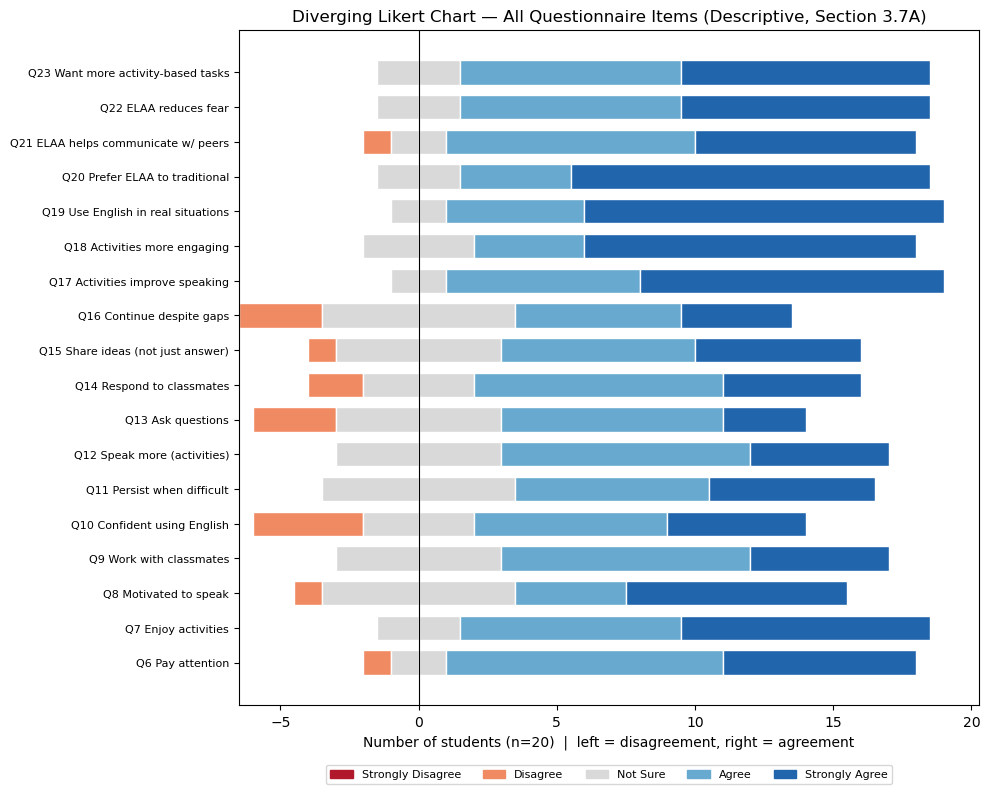


[FIGURE 2] Construct-level mean scores with SD error bars.
  Visualises the composite construct means already reported in Section
  3.7(B): Engagement -> Communicative Behaviour -> Student Perceptions of ELAA,
  matching the order of the conceptual framework in 2.9.


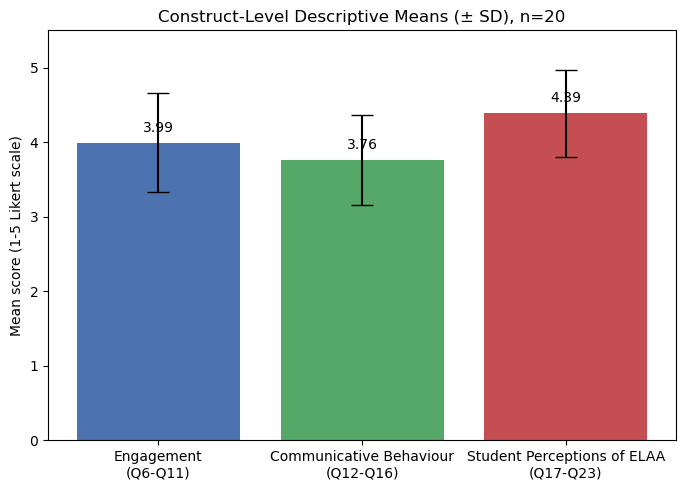


[FIGURE 3] Boxplots of total questionnaire score by gender and by
  self-rated speaking level. Descriptive spread only (Section 3.7C) —
  group sizes are small, so this shows distribution shape, not a
  statistically tested group difference.


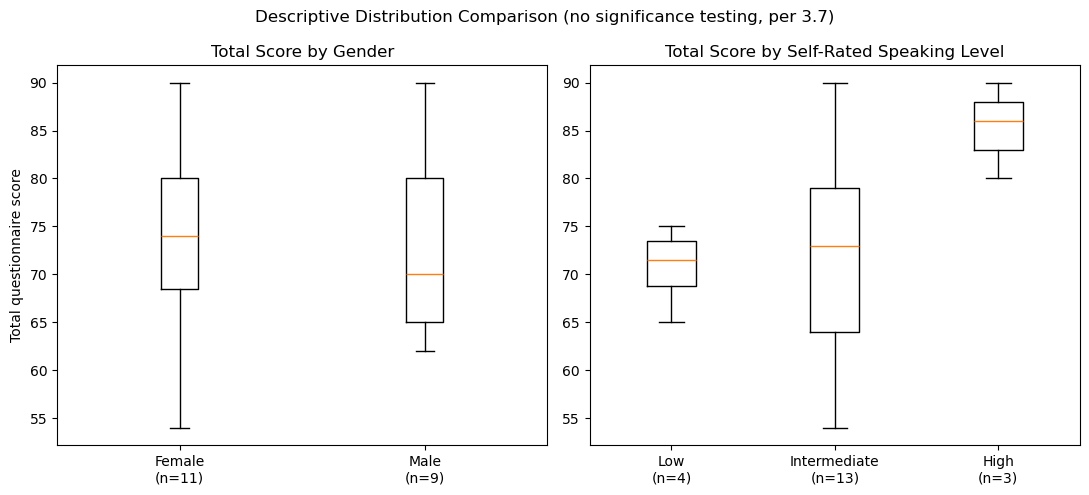


[FIGURE 4] Correlation matrix heatmap — EXPLORATORY / SUPPLEMENTARY.
  This goes beyond the core descriptive design in 3.7. It is included only
  to visualise whether item-level patterns are broadly consistent with the
  conceptual framework's proposed link (2.9): engagement -> communicative
  behaviour -> perception. On n=20, correlation coefficients are reported
  descriptively — NOT as hypothesis tests, and NOT as evidence of causality
  (consistent with the no-control-group limitation in 3.10).


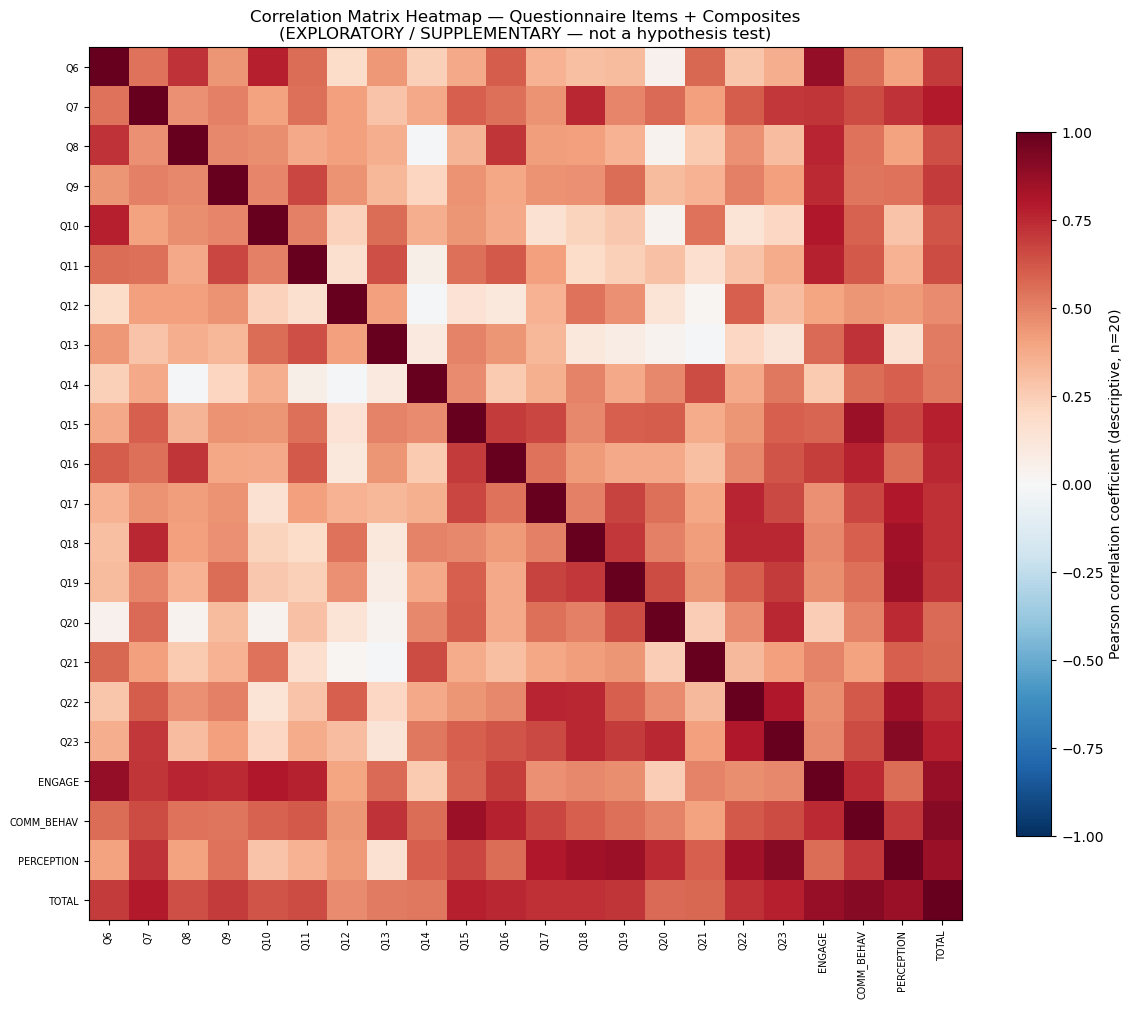


  Descriptive construct correlations (n=20, exploratory only):
    Engagement <-> Communicative Behaviour : r = 0.74
    Communicative Behaviour <-> Perception  : r = 0.71
    Engagement <-> Perception                : r = 0.56
  These are reported as descriptive patterns to support triangulation with
  the qualitative theme frequencies below — not as confirmatory statistics.

[FIGURE 5] Scatterplot — Engagement vs Communicative Behaviour composites.
  Directly visualises the first link in the conceptual framework (2.9).
  Exploratory / descriptive only, consistent with Figure 4 above.


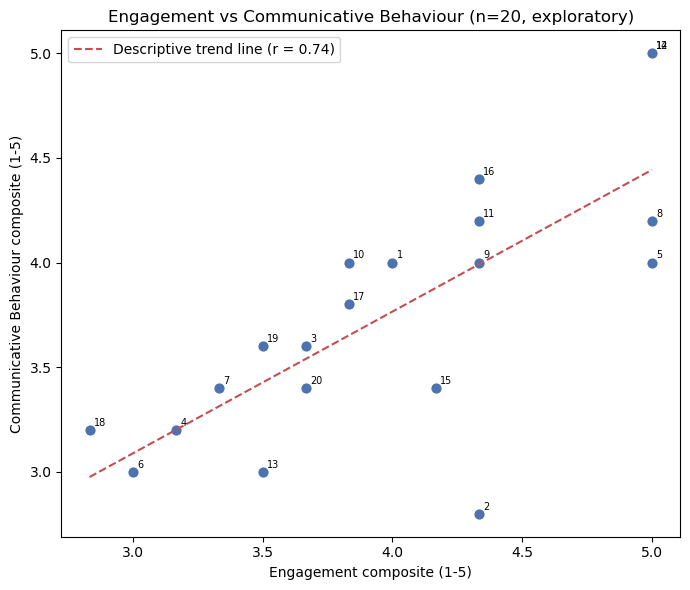


[FIGURE 6] Feature importance — ILLUSTRATIVE / EXPLORATORY ONLY.
  This is the analysis furthest from the core methodology. On n=20, any
  predictive model is at serious risk of overfitting, and results here
  are NOT generalisable and NOT a claim of which activities 'cause' higher
  scores. It exists only as a discussion prompt, consistent with the
  methodology's own rejection of causal claims (3.10: 'lacks a control
  group; the research is not able to generate causality').
  scikit-learn detected — fitting a small RandomForestRegressor to predict
  each student's Total questionnaire score from the 18 individual items.


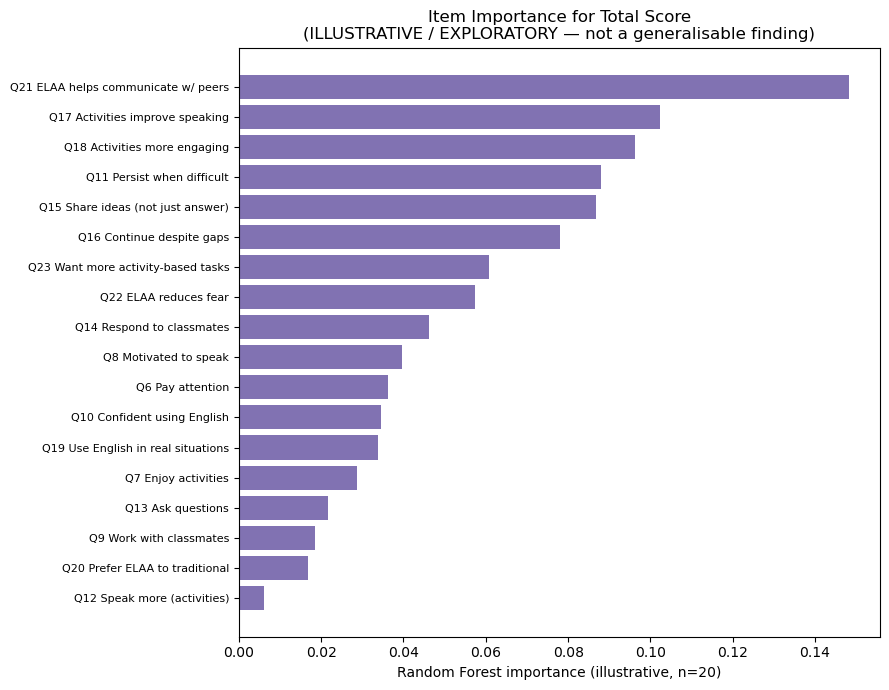


  Top 3 items most associated with Total score in this exploratory analysis:
    - Q21 ELAA helps communicate w/ peers  (Random Forest importance = 0.148)
    - Q17 Activities improve speaking  (Random Forest importance = 0.102)
    - Q18 Activities more engaging  (Random Forest importance = 0.096)
  Reminder: with n=20 and no held-out test set, this ranking should be
  treated as a discussion prompt for the qualitative chapters, not a result.

[FIGURE 7] Teacher interview theme frequency (deductive + inductive codes).
  Visualises the thematic coding counts from Section 3.7's qualitative
  strand — supports the triangulation step, does not introduce new claims.


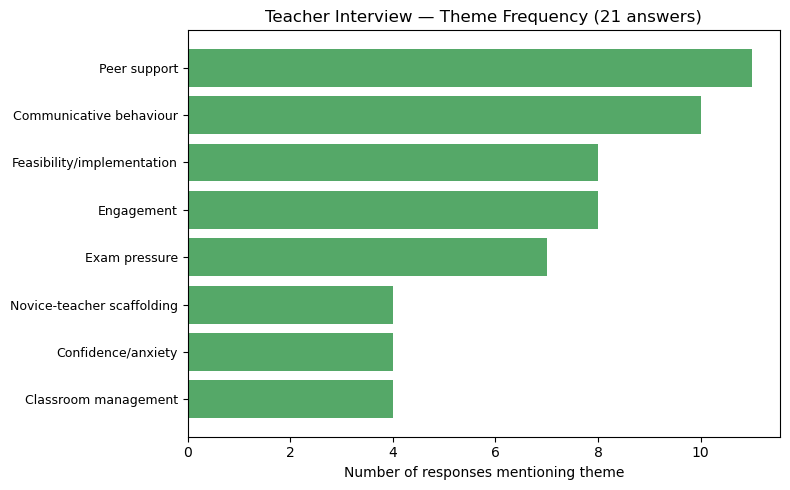


[FIGURE 8] Open-ended student comment (Q24) theme frequency (inductive codes).


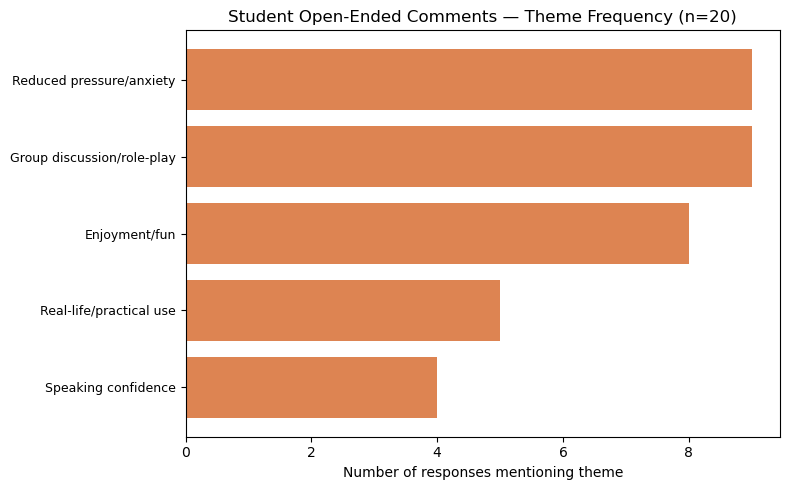


SUMMARY: HOW THIS SET OF FIGURES MAPS TO THE METHODOLOGY
Figures 1-3 are descriptive visualisations of the numbers already reported
under Section 3.7's non-inferential design. Figures 4-6 are explicitly
exploratory/supplementary additions that go beyond the core methodology and
are labelled as such in their titles and console output; none of them are
treated as confirmatory or causal, consistent with the limitations in Section
3.10 (no control group, small sample, no inferential testing). Figures 7-8
visualise the deductive and inductive thematic coding from the qualitative
strand and directly support the triangulation step described at the end of
Section 3.7.

END OF VISUAL ANALYSIS


In [11]:
import statistics
import textwrap
from collections import Counter, defaultdict

import numpy as np
import matplotlib

# Auto-detect environment: use inline rendering in Jupyter/VS Code notebooks
# (where the default Agg backend silently swallows plt.show()), and fall back
# to an interactive GUI backend when run as a plain .py script in a terminal.
try:
    get_ipython().run_line_magic('matplotlib', 'inline')
except NameError:
    matplotlib.use('TkAgg')

import matplotlib.pyplot as plt

# scikit-learn is optional — the script still runs fully without it
try:
    from sklearn.ensemble import RandomForestRegressor
    SKLEARN_AVAILABLE = True
except ImportError:
    SKLEARN_AVAILABLE = False


# ==============================================================================
# 1. LIKERT ENCODING + CONSTRUCT GROUPING (same as core analysis script)
# ==============================================================================
LIKERT_MAP = {"Strongly Disagree": 1, "Disagree": 2, "Not Sure": 3, "Agree": 4, "Strongly Agree": 5}
LIKERT_ORDER = ["Strongly Disagree", "Disagree", "Not Sure", "Agree", "Strongly Agree"]

ENGAGEMENT_ITEMS = ["q6", "q7", "q8", "q9", "q10", "q11"]
COMM_BEHAVIOUR_ITEMS = ["q12", "q13", "q14", "q15", "q16"]
PERCEPTION_ITEMS = ["q17", "q18", "q19", "q20", "q21", "q22", "q23"]
ALL_ITEMS = ENGAGEMENT_ITEMS + COMM_BEHAVIOUR_ITEMS + PERCEPTION_ITEMS

ITEM_LABELS = {
    "q6": "Q6 Pay attention", "q7": "Q7 Enjoy activities", "q8": "Q8 Motivated to speak",
    "q9": "Q9 Work with classmates", "q10": "Q10 Confident using English",
    "q11": "Q11 Persist when difficult",
    "q12": "Q12 Speak more (activities)", "q13": "Q13 Ask questions",
    "q14": "Q14 Respond to classmates", "q15": "Q15 Share ideas (not just answer)",
    "q16": "Q16 Continue despite gaps",
    "q17": "Q17 Activities improve speaking", "q18": "Q18 Activities more engaging",
    "q19": "Q19 Use English in real situations", "q20": "Q20 Prefer ELAA to traditional",
    "q21": "Q21 ELAA helps communicate w/ peers", "q22": "Q22 ELAA reduces fear",
    "q23": "Q23 Want more activity-based tasks",
}


# ==============================================================================
# 2. EMBEDDED STUDENT QUESTIONNAIRE DATA (n = 20)
# ==============================================================================
STUDENTS = [
    dict(id=1, total=79, gender="Female", level="Intermediate",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree",
         q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=2, total=64, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Not Sure", q14="Disagree", q15="Disagree", q16="Not Sure",
         q17="Not Sure", q18="Agree", q19="Agree", q20="Not Sure", q21="Agree", q22="Not Sure", q23="Not Sure"),
    dict(id=3, total=68, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=4, total=61, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Agree", q10="Disagree", q11="Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Not Sure", q16="Disagree",
         q17="Strongly Agree", q18="Not Sure", q19="Agree", q20="Agree", q21="Not Sure", q22="Agree", q23="Not Sure"),
    dict(id=5, total=82, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Agree"),
    dict(id=6, total=54, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Not Sure", q18="Not Sure", q19="Not Sure", q20="Not Sure", q21="Not Sure", q22="Not Sure", q23="Not Sure"),
    dict(id=7, total=65, gender="Male", level="Low",
         q6="Agree", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Not Sure", q23="Agree"),
    dict(id=8, total=86, gender="Male", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Not Sure", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=9, total=78, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Strongly Agree", q11="Not Sure",
         q12="Strongly Agree", q13="Agree", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Not Sure", q21="Strongly Agree", q22="Strongly Agree", q23="Agree"),
    dict(id=10, total=73, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Agree", q13="Agree", q14="Strongly Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Strongly Agree", q19="Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=11, total=81, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Not Sure", q9="Agree", q10="Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Strongly Agree"),
    dict(id=12, total=90, gender="Male", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=13, total=62, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Not Sure", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=14, total=90, gender="Female", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=15, total=75, gender="Male", level="Low",
         q6="Agree", q7="Strongly Agree", q8="Not Sure", q9="Strongly Agree", q10="Agree", q11="Agree",
         q12="Strongly Agree", q13="Not Sure", q14="Agree", q15="Not Sure", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=16, total=80, gender="Male", level="High",
         q6="Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Agree", q10="Not Sure", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Disagree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Disagree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=17, total=70, gender="Male", level="Low",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=18, total=64, gender="Male", level="Intermediate",
         q6="Disagree", q7="Agree", q8="Disagree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=19, total=74, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=20, total=73, gender="Female", level="Low",
         q6="Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Not Sure", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree"),
]

# ==============================================================================
# 3. TEACHER INTERVIEW + THEME KEYWORDS (for thematic frequency charts)
# ==============================================================================
TEACHER_ANSWERS = [
    "I have been teaching English for about one year. I am still a relatively new teacher, developing my classroom management and teaching skills.",
    "I currently teach Grade 10 students in a senior high school.",
    "No, I had not used activity-based or communicative teaching methods before. Teachers focus more on examination results, grammar, vocabulary and reading because of exam pressure, so I mainly used traditional teacher-centred methods.",
    "I understood ELAA as increasing participation and giving opportunities to use English in real situations through meaningful activities rather than only explanation and memorisation.",
    "It was difficult at first because I was not familiar with the approach and needed to consider the teaching schedule and exam preparation. After several lessons I became more comfortable organising activities.",
    "Pair discussions, group discussions and short role-play activities worked best, allowing students to share ideas and practise speaking in a less stressful environment.",
    "Some longer speaking tasks did not work well. A few students were not confident enough to speak for an extended period, some groups became off-task, and time management was a challenge.",
    "Most students responded positively and seemed more active than in traditional lessons, especially working with classmates.",
    "More students were willing to answer questions and participate; quieter students also contributed during ELAA activities, unlike traditional lessons where the same students usually spoke.",
    "Many students appeared more interested because lessons were more interactive, enjoying exchanging opinions and completing tasks together.",
    "A small number of students remained passive, mainly because of limited speaking ability, lack of confidence, and fear of making mistakes in front of classmates.",
    "Students used English more actively to express opinions, ask questions and respond to classmates, rather than short fixed responses to the teacher.",
    "Students interacted more with classmates: turn-taking, asking for clarification, agreeing and disagreeing, helping each other find words.",
    "Some students became more confident; one usually quiet student volunteered to report the group's ideas to the class.",
    "I observed students asking questions, responding to peers, giving opinions, explaining ideas, and negotiating meaning when unclear.",
    "The main challenges were classroom management, controlling noise levels, and ensuring students used English rather than Chinese.",
    "Class size, time limits, exam pressure and curriculum requirements all affected the use of ELAA; exam pressure is very strong in China.",
    "At first it was difficult to manage students because I had only one year of experience and my classroom management skills were still developing; some students became too excited during group work.",
    "Teachers would need training on designing communicative tasks, managing group activities, and assessing performance, plus more resources and examples.",
    "Yes, ELAA is useful for improving engagement because students have more chances to participate actively and cooperate, and the classroom atmosphere becomes more lively.",
    "Yes, ELAA can help improve communicative competence: practising expressing ideas, listening, and responding in English, skills not fully developed through grammar-focused teaching.",
    "ELAA is more interactive and student-centred; traditional teaching may be more efficient for grammar and test-taking but ELAA provides more real communication.",
    "Yes, I would continue using ELAA, probably combined with traditional methods to balance communicative practice with exam preparation.",
    "As a new teacher this was challenging but valuable; students are more engaged when given meaningful tasks, and I hope to learn to adapt ELAA to the Chinese context while meeting exam requirements.",
]

STUDENT_COMMENTS = [
    "I love fun group games and interactive tasks, which let me use words freely without heavy memorization pressure.",
    "I can have the real chance to use English.",
    "I loved that these activities focused on real-life language application instead of rigid textbook memorization, practising speaking freely without much pressure.",
    "They combine real-life communication with language learning instead of rigid textbook drills. I no longer feel nervous about opening my mouth in English.",
    "It helps speak more.",
    "The activities were highly interactive and practical. I enjoyed working in groups because it gave me more opportunities to practice speaking without feeling too pressured.",
    "reading",
    "I love the interactive group tasks most. It greatly improves my willingness to speak English bravely.",
    "The ELAA framework perfectly balanced fun and practicality without making learners feel pressured.",
    "The interesting and various activities which can help me learn and use English better.",
    "I love the group discussion parts most. We can freely share ideas with classmates instead of just listening to teachers.",
    "I love the group discussions. They let me practice English freely with classmates.",
    "My favorite ELAA-based activities are role-play conversations and free group discussions.",
    "Role-play, group discussion, English debate, English speech, and situational teaching used in class.",
    "ELAA replaces boring traditional textbook teaching with lots of interactive practice. I can practice my oral English naturally without pressure.",
    "Some task based activities, group discussions, games, debates.",
    "Role-play",
    "I like group discussions and role-play.",
    "I like the situational approach in English teaching.",
    "I liked the group discussions best. We could freely share our ideas with partners, which made learning fun and relaxing.",
]

THEME_KEYWORDS_TEACHER = {
    "Engagement": ["active", "engag", "motivat", "interest", "particip", "responded positively", "enjoy", "willing", "contribut", "lively"],
    "Communicative behaviour": ["ask questions", "respond", "turn-taking", "clarification", "negotiat", "express", "opinions", "interact", "communicat", "explain"],
    "Feasibility/implementation": ["difficult", "challenge", "manage", "schedule", "exam preparation", "curriculum", "training", "resources", "time management"],
    "Confidence/anxiety": ["confiden", "afraid", "fear", "nervous", "shy", "quiet", "mistakes"],
    "Exam pressure": ["exam", "test", "score", "curriculum", "pressure"],
    "Peer support": ["classmates", "group", "pair", "cooperat", "each other", "peer"],
    "Classroom management": ["noise", "off-task", "rules", "time limit", "discipline", "excited", "control"],
    "Novice-teacher scaffolding": ["new teacher", "one year", "developing", "not familiar", "comfortable", "experience"],
}

THEME_KEYWORDS_STUDENT = {
    "Enjoyment/fun": ["fun", "love", "enjoy", "relax", "lively"],
    "Reduced pressure/anxiety": ["pressure", "nervous", "without pressure", "freely", "afraid"],
    "Real-life/practical use": ["real-life", "real situations", "practical", "naturally", "in daily"],
    "Group discussion/role-play": ["group discussion", "role-play", "role play", "debate", "situational"],
    "Speaking confidence": ["confidence", "willing", "bravely", "speak"],
}


def code_frequency(texts, keyword_dict):
    counts = Counter()
    for text in texts:
        text_lower = text.lower()
        for theme, keywords in keyword_dict.items():
            if any(kw.lower() in text_lower for kw in keywords):
                counts[theme] += 1
    return counts


# ==============================================================================
# 4. NUMERIC DATA MATRIX
# ==============================================================================
def build_matrix():
    """n_students x n_items numeric matrix, plus composite + total arrays."""
    matrix = np.array([[LIKERT_MAP[s[item]] for item in ALL_ITEMS] for s in STUDENTS], dtype=float)
    engagement = matrix[:, [ALL_ITEMS.index(i) for i in ENGAGEMENT_ITEMS]].mean(axis=1)
    comm = matrix[:, [ALL_ITEMS.index(i) for i in COMM_BEHAVIOUR_ITEMS]].mean(axis=1)
    perception = matrix[:, [ALL_ITEMS.index(i) for i in PERCEPTION_ITEMS]].mean(axis=1)
    total = np.array([s["total"] for s in STUDENTS], dtype=float)
    return matrix, engagement, comm, perception, total


# ==============================================================================
# 5. FIGURE 1 — DIVERGING STACKED BAR CHART (descriptive, Section 3.7 A)
# ==============================================================================
def figure_likert_diverging():
    print("\n[FIGURE 1] Diverging stacked bar chart of all 18 Likert items.")
    print("  Purely descriptive visualisation of the frequency distributions already")
    print("  reported in Section 3.7(A) — no new statistical claim is introduced.")

    n = len(STUDENTS)
    colors = {"Strongly Disagree": "#b2182b", "Disagree": "#ef8a62", "Not Sure": "#d9d9d9",
              "Agree": "#67a9cf", "Strongly Agree": "#2166ac"}

    fig, ax = plt.subplots(figsize=(10, 8))
    y_positions = np.arange(len(ALL_ITEMS))

    for idx, item in enumerate(ALL_ITEMS):
        counts = Counter(s[item] for s in STUDENTS)
        sd, d, ns, a, sa = (counts.get(k, 0) for k in LIKERT_ORDER)
        left_edge = -(sd + d + ns / 2)
        cursor = left_edge
        # ordered segments summing to sd, d, ns/2, ns/2, a, sa
        segments = [("Strongly Disagree", sd), ("Disagree", d), ("Not Sure", ns / 2),
                    ("Not Sure", ns / 2), ("Agree", a), ("Strongly Agree", sa)]
        for label, value in segments:
            if value > 0:
                ax.barh(idx, value, left=cursor, color=colors[label], edgecolor="white", height=0.7)
            cursor += value

    ax.axvline(0, color="black", linewidth=0.8)
    ax.set_yticks(y_positions)
    ax.set_yticklabels([ITEM_LABELS[i] for i in ALL_ITEMS], fontsize=8)
    ax.set_xlabel(f"Number of students (n={n})  |  left = disagreement, right = agreement")
    ax.set_title("Diverging Likert Chart — All Questionnaire Items (Descriptive, Section 3.7A)")
    handles = [plt.Rectangle((0, 0), 1, 1, color=colors[k]) for k in LIKERT_ORDER]
    ax.legend(handles, LIKERT_ORDER, loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, fontsize=8)
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 6. FIGURE 2 — CONSTRUCT MEANS BAR CHART WITH SD ERROR BARS (descriptive)
# ==============================================================================
def figure_construct_means(engagement, comm, perception):
    print("\n[FIGURE 2] Construct-level mean scores with SD error bars.")
    print("  Visualises the composite construct means already reported in Section")
    print("  3.7(B): Engagement -> Communicative Behaviour -> Student Perceptions of ELAA,")
    print("  matching the order of the conceptual framework in 2.9.")

    labels = ["Engagement\n(Q6-Q11)", "Communicative Behaviour\n(Q12-Q16)", "Student Perceptions of ELAA\n(Q17-Q23)"]
    means = [engagement.mean(), comm.mean(), perception.mean()]
    sds = [engagement.std(), comm.std(), perception.std()]

    fig, ax = plt.subplots(figsize=(7, 5))
    bars = ax.bar(labels, means, yerr=sds, capsize=8, color=["#4C72B0", "#55A868", "#C44E52"])
    ax.set_ylim(0, 5.5)
    ax.set_ylabel("Mean score (1-5 Likert scale)")
    ax.set_title("Construct-Level Descriptive Means (± SD), n=20")
    for bar, mean in zip(bars, means):
        ax.text(bar.get_x() + bar.get_width() / 2, mean + 0.15, f"{mean:.2f}", ha="center", fontsize=10)
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 7. FIGURE 3 — GROUPED BOXPLOTS BY GENDER AND SPEAKING LEVEL (descriptive)
# ==============================================================================
def figure_boxplots_by_group(total):
    print("\n[FIGURE 3] Boxplots of total questionnaire score by gender and by")
    print("  self-rated speaking level. Descriptive spread only (Section 3.7C) —")
    print("  group sizes are small, so this shows distribution shape, not a")
    print("  statistically tested group difference.")

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))

    gender_groups = defaultdict(list)
    for s, t in zip(STUDENTS, total):
        gender_groups[s["gender"]].append(t)
    axes[0].boxplot(gender_groups.values(), tick_labels=[f"{g}\n(n={len(v)})" for g, v in gender_groups.items()])
    axes[0].set_title("Total Score by Gender")
    axes[0].set_ylabel("Total questionnaire score")

    level_groups = defaultdict(list)
    for s, t in zip(STUDENTS, total):
        level_groups[s["level"]].append(t)
    order = ["Low", "Intermediate", "High"]
    ordered_items = [(lvl, level_groups[lvl]) for lvl in order if lvl in level_groups]
    axes[1].boxplot([v for _, v in ordered_items], tick_labels=[f"{lvl}\n(n={len(v)})" for lvl, v in ordered_items])
    axes[1].set_title("Total Score by Self-Rated Speaking Level")

    plt.suptitle("Descriptive Distribution Comparison (no significance testing, per 3.7)")
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 8. FIGURE 4 — CORRELATION MATRIX HEATMAP (exploratory / supplementary)
# ==============================================================================
def figure_correlation_heatmap(matrix, engagement, comm, perception, total):
    print("\n[FIGURE 4] Correlation matrix heatmap — EXPLORATORY / SUPPLEMENTARY.")
    print("  This goes beyond the core descriptive design in 3.7. It is included only")
    print("  to visualise whether item-level patterns are broadly consistent with the")
    print("  conceptual framework's proposed link (2.9): engagement -> communicative")
    print("  behaviour -> perception. On n=20, correlation coefficients are reported")
    print("  descriptively — NOT as hypothesis tests, and NOT as evidence of causality")
    print("  (consistent with the no-control-group limitation in 3.10).")

    combined = np.column_stack([matrix, engagement, comm, perception, total])
    combined_labels = [ITEM_LABELS[i].split(" ", 1)[0] for i in ALL_ITEMS] + \
        ["ENGAGE", "COMM_BEHAV", "PERCEPTION", "TOTAL"]
    corr = np.corrcoef(combined.T)

    fig, ax = plt.subplots(figsize=(12, 10))
    im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(combined_labels)))
    ax.set_yticks(range(len(combined_labels)))
    ax.set_xticklabels(combined_labels, rotation=90, fontsize=7)
    ax.set_yticklabels(combined_labels, fontsize=7)
    cbar = fig.colorbar(im, ax=ax, shrink=0.8)
    cbar.set_label("Pearson correlation coefficient (descriptive, n=20)")
    ax.set_title("Correlation Matrix Heatmap — Questionnaire Items + Composites\n(EXPLORATORY / SUPPLEMENTARY — not a hypothesis test)")
    plt.tight_layout()
    plt.show()

    # Print the strongest descriptive relationship between the three core
    # constructs, directly supporting the triangulation step in 3.7.
    r_engage_comm = np.corrcoef(engagement, comm)[0, 1]
    r_comm_percep = np.corrcoef(comm, perception)[0, 1]
    r_engage_percep = np.corrcoef(engagement, perception)[0, 1]
    print(f"\n  Descriptive construct correlations (n=20, exploratory only):")
    print(f"    Engagement <-> Communicative Behaviour : r = {r_engage_comm:.2f}")
    print(f"    Communicative Behaviour <-> Perception  : r = {r_comm_percep:.2f}")
    print(f"    Engagement <-> Perception                : r = {r_engage_percep:.2f}")
    print("  These are reported as descriptive patterns to support triangulation with")
    print("  the qualitative theme frequencies below — not as confirmatory statistics.")


# ==============================================================================
# 9. FIGURE 5 — SCATTERPLOT: ENGAGEMENT vs COMMUNICATIVE BEHAVIOUR (exploratory)
# ==============================================================================
def figure_scatter_engagement_comm(engagement, comm):
    print("\n[FIGURE 5] Scatterplot — Engagement vs Communicative Behaviour composites.")
    print("  Directly visualises the first link in the conceptual framework (2.9).")
    print("  Exploratory / descriptive only, consistent with Figure 4 above.")

    r = np.corrcoef(engagement, comm)[0, 1]
    fig, ax = plt.subplots(figsize=(7, 6))
    ax.scatter(engagement, comm, s=70, color="#4C72B0", edgecolor="white")
    for s, e, c in zip(STUDENTS, engagement, comm):
        ax.annotate(str(s["id"]), (e, c), fontsize=7, xytext=(3, 3), textcoords="offset points")
    # simple least-squares line, shown descriptively (not a formal regression model)
    coeffs = np.polyfit(engagement, comm, 1)
    x_line = np.linspace(engagement.min(), engagement.max(), 50)
    ax.plot(x_line, np.polyval(coeffs, x_line), color="#C44E52", linestyle="--",
            label=f"Descriptive trend line (r = {r:.2f})")
    ax.set_xlabel("Engagement composite (1-5)")
    ax.set_ylabel("Communicative Behaviour composite (1-5)")
    ax.set_title("Engagement vs Communicative Behaviour (n=20, exploratory)")
    ax.legend()
    plt.tight_layout()
    plt.show()


# ==============================================================================
# 10. FIGURE 6 — "FEATURE IMPORTANCE" (illustrative exploratory add-on ONLY)
# ==============================================================================
def figure_feature_importance(matrix, total):
    print("\n[FIGURE 6] Feature importance — ILLUSTRATIVE / EXPLORATORY ONLY.")
    print("  This is the analysis furthest from the core methodology. On n=20, any")
    print("  predictive model is at serious risk of overfitting, and results here")
    print("  are NOT generalisable and NOT a claim of which activities 'cause' higher")
    print("  scores. It exists only as a discussion prompt, consistent with the")
    print("  methodology's own rejection of causal claims (3.10: 'lacks a control")
    print("  group; the research is not able to generate causality').")

    if SKLEARN_AVAILABLE:
        print("  scikit-learn detected — fitting a small RandomForestRegressor to predict")
        print("  each student's Total questionnaire score from the 18 individual items.")
        model = RandomForestRegressor(n_estimators=300, max_depth=3, random_state=42)
        model.fit(matrix, total)
        importances = model.feature_importances_
        method_label = "Random Forest importance (illustrative, n=20)"
    else:
        print("  scikit-learn not available — falling back to a correlation-based proxy")
        print("  (|Pearson r| between each item and Total score). No modelling assumptions.")
        importances = np.array([abs(np.corrcoef(matrix[:, i], total)[0, 1]) for i in range(matrix.shape[1])])
        method_label = "|Correlation with Total| (fallback proxy, n=20)"

    order = np.argsort(importances)[::-1]
    sorted_labels = [ITEM_LABELS[ALL_ITEMS[i]] for i in order]
    sorted_importances = importances[order]

    fig, ax = plt.subplots(figsize=(9, 7))
    ax.barh(range(len(sorted_labels)), sorted_importances[::-1], color="#8172B2")
    ax.set_yticks(range(len(sorted_labels)))
    ax.set_yticklabels(sorted_labels[::-1], fontsize=8)
    ax.set_xlabel(method_label)
    ax.set_title("Item Importance for Total Score\n(ILLUSTRATIVE / EXPLORATORY — not a generalisable finding)")
    plt.tight_layout()
    plt.show()

    print("\n  Top 3 items most associated with Total score in this exploratory analysis:")
    for i in order[:3]:
        print(f"    - {ITEM_LABELS[ALL_ITEMS[i]]}  ({method_label.split(' (')[0]} = {importances[i]:.3f})")
    print("  Reminder: with n=20 and no held-out test set, this ranking should be")
    print("  treated as a discussion prompt for the qualitative chapters, not a result.")


# ==============================================================================
# 11. FIGURE 7 & 8 — THEMATIC FREQUENCY BAR CHARTS (Section 3.7, thematic analysis)
# ==============================================================================
def figure_theme_frequency(counts, title, color):
    fig, ax = plt.subplots(figsize=(8, 5))
    themes, values = zip(*sorted(counts.items(), key=lambda x: x[1], reverse=True))
    ax.barh(range(len(themes)), values, color=color)
    ax.set_yticks(range(len(themes)))
    ax.set_yticklabels(themes, fontsize=9)
    ax.invert_yaxis()
    ax.set_xlabel("Number of responses mentioning theme")
    ax.set_title(title)
    plt.tight_layout()
    plt.show()


def figure_teacher_theme_frequency():
    print("\n[FIGURE 7] Teacher interview theme frequency (deductive + inductive codes).")
    print("  Visualises the thematic coding counts from Section 3.7's qualitative")
    print("  strand — supports the triangulation step, does not introduce new claims.")
    counts = code_frequency(TEACHER_ANSWERS, THEME_KEYWORDS_TEACHER)
    figure_theme_frequency(counts, "Teacher Interview — Theme Frequency (21 answers)", "#55A868")
    return counts


def figure_student_theme_frequency():
    print("\n[FIGURE 8] Open-ended student comment (Q24) theme frequency (inductive codes).")
    counts = code_frequency(STUDENT_COMMENTS, THEME_KEYWORDS_STUDENT)
    figure_theme_frequency(counts, "Student Open-Ended Comments — Theme Frequency (n=20)", "#DD8452")
    return counts


# ==============================================================================
# 12. MAIN
# ==============================================================================
def main():
    print("#" * 78)
    print("# ELAA STUDY — VISUAL / EXPLORATORY ANALYSIS")
    print("# All figures are displayed via plt.show() (interactive windows).")
    print("# All numeric results are printed to the terminal.")
    print("# NOTHING is saved to disk — no PNG/CSV/XLSX files are created.")
    print("#" * 78)

    matrix, engagement, comm, perception, total = build_matrix()

    # --- Core descriptive figures (fully within the stated methodology) ---
    figure_likert_diverging()
    figure_construct_means(engagement, comm, perception)
    figure_boxplots_by_group(total)

    # --- Exploratory / supplementary figures (clearly flagged as such) ---
    figure_correlation_heatmap(matrix, engagement, comm, perception, total)
    figure_scatter_engagement_comm(engagement, comm)
    figure_feature_importance(matrix, total)

    # --- Thematic (qualitative) frequency figures, supporting triangulation ---
    teacher_counts = figure_teacher_theme_frequency()
    student_counts = figure_student_theme_frequency()

    print("\n" + "=" * 78)
    print("SUMMARY: HOW THIS SET OF FIGURES MAPS TO THE METHODOLOGY")
    print("=" * 78)
    print(textwrap.fill(
        "Figures 1-3 are descriptive visualisations of the numbers already "
        "reported under Section 3.7's non-inferential design. Figures 4-6 are "
        "explicitly exploratory/supplementary additions that go beyond the core "
        "methodology and are labelled as such in their titles and console output; "
        "none of them are treated as confirmatory or causal, consistent with the "
        "limitations in Section 3.10 (no control group, small sample, no "
        "inferential testing). Figures 7-8 visualise the deductive and inductive "
        "thematic coding from the qualitative strand and directly support the "
        "triangulation step described at the end of Section 3.7.", width=78))
    print("\nEND OF VISUAL ANALYSIS")


if __name__ == "__main__":
    main()

In [9]:
import statistics
from collections import Counter, defaultdict

import numpy as np

try:
    from sklearn.ensemble import RandomForestRegressor
    SKLEARN_AVAILABLE = True
except ImportError:
    SKLEARN_AVAILABLE = False


# ==============================================================================
# 1. LIKERT ENCODING + CONSTRUCT GROUPING
# ==============================================================================
LIKERT_MAP = {"Strongly Disagree": 1, "Disagree": 2, "Not Sure": 3, "Agree": 4, "Strongly Agree": 5}
LIKERT_ORDER = ["Strongly Disagree", "Disagree", "Not Sure", "Agree", "Strongly Agree"]

ENGAGEMENT_ITEMS = ["q6", "q7", "q8", "q9", "q10", "q11"]
COMM_BEHAVIOUR_ITEMS = ["q12", "q13", "q14", "q15", "q16"]
PERCEPTION_ITEMS = ["q17", "q18", "q19", "q20", "q21", "q22", "q23"]
ALL_ITEMS = ENGAGEMENT_ITEMS + COMM_BEHAVIOUR_ITEMS + PERCEPTION_ITEMS

ITEM_LABELS = {
    "q6": "Q6 Pay attention", "q7": "Q7 Enjoy activities", "q8": "Q8 Motivated to speak",
    "q9": "Q9 Work with classmates", "q10": "Q10 Confident using English",
    "q11": "Q11 Persist when difficult",
    "q12": "Q12 Speak more (activities)", "q13": "Q13 Ask questions",
    "q14": "Q14 Respond to classmates", "q15": "Q15 Share ideas (not just answer)",
    "q16": "Q16 Continue despite gaps",
    "q17": "Q17 Activities improve speaking", "q18": "Q18 Activities more engaging",
    "q19": "Q19 Use English in real situations", "q20": "Q20 Prefer ELAA to traditional",
    "q21": "Q21 ELAA helps communicate w/ peers", "q22": "Q22 ELAA reduces fear",
    "q23": "Q23 Want more activity-based tasks",
}


# ==============================================================================
# 2. EMBEDDED STUDENT QUESTIONNAIRE DATA (n = 20)
# ==============================================================================
STUDENTS = [
    dict(id=1, total=79, gender="Female", level="Intermediate",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree",
         q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=2, total=64, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Not Sure", q14="Disagree", q15="Disagree", q16="Not Sure",
         q17="Not Sure", q18="Agree", q19="Agree", q20="Not Sure", q21="Agree", q22="Not Sure", q23="Not Sure"),
    dict(id=3, total=68, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=4, total=61, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Agree", q10="Disagree", q11="Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Not Sure", q16="Disagree",
         q17="Strongly Agree", q18="Not Sure", q19="Agree", q20="Agree", q21="Not Sure", q22="Agree", q23="Not Sure"),
    dict(id=5, total=82, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Agree"),
    dict(id=6, total=54, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Not Sure", q18="Not Sure", q19="Not Sure", q20="Not Sure", q21="Not Sure", q22="Not Sure", q23="Not Sure"),
    dict(id=7, total=65, gender="Male", level="Low",
         q6="Agree", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Not Sure", q23="Agree"),
    dict(id=8, total=86, gender="Male", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Not Sure", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=9, total=78, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Strongly Agree", q11="Not Sure",
         q12="Strongly Agree", q13="Agree", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Not Sure", q21="Strongly Agree", q22="Strongly Agree", q23="Agree"),
    dict(id=10, total=73, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Agree", q13="Agree", q14="Strongly Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Strongly Agree", q19="Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=11, total=81, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Not Sure", q9="Agree", q10="Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Strongly Agree"),
    dict(id=12, total=90, gender="Male", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=13, total=62, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Not Sure", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=14, total=90, gender="Female", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=15, total=75, gender="Male", level="Low",
         q6="Agree", q7="Strongly Agree", q8="Not Sure", q9="Strongly Agree", q10="Agree", q11="Agree",
         q12="Strongly Agree", q13="Not Sure", q14="Agree", q15="Not Sure", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=16, total=80, gender="Male", level="High",
         q6="Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Agree", q10="Not Sure", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Disagree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Disagree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=17, total=70, gender="Male", level="Low",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=18, total=64, gender="Male", level="Intermediate",
         q6="Disagree", q7="Agree", q8="Disagree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=19, total=74, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=20, total=73, gender="Female", level="Low",
         q6="Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Not Sure", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree"),
]

# ==============================================================================
# 3. TEACHER INTERVIEW + STUDENT COMMENTS + THEME KEYWORDS
# ==============================================================================
TEACHER_ANSWERS = [
    "I have been teaching English for about one year. I am still a relatively new teacher, developing my classroom management and teaching skills.",
    "I currently teach Grade 10 students in a senior high school.",
    "No, I had not used activity-based or communicative teaching methods before. Teachers focus more on examination results, grammar, vocabulary and reading because of exam pressure, so I mainly used traditional teacher-centred methods.",
    "I understood ELAA as increasing participation and giving opportunities to use English in real situations through meaningful activities rather than only explanation and memorisation.",
    "It was difficult at first because I was not familiar with the approach and needed to consider the teaching schedule and exam preparation. After several lessons I became more comfortable organising activities.",
    "Pair discussions, group discussions and short role-play activities worked best, allowing students to share ideas and practise speaking in a less stressful environment.",
    "Some longer speaking tasks did not work well. A few students were not confident enough to speak for an extended period, some groups became off-task, and time management was a challenge.",
    "Most students responded positively and seemed more active than in traditional lessons, especially working with classmates.",
    "More students were willing to answer questions and participate; quieter students also contributed during ELAA activities, unlike traditional lessons where the same students usually spoke.",
    "Many students appeared more interested because lessons were more interactive, enjoying exchanging opinions and completing tasks together.",
    "A small number of students remained passive, mainly because of limited speaking ability, lack of confidence, and fear of making mistakes in front of classmates.",
    "Students used English more actively to express opinions, ask questions and respond to classmates, rather than short fixed responses to the teacher.",
    "Students interacted more with classmates: turn-taking, asking for clarification, agreeing and disagreeing, helping each other find words.",
    "Some students became more confident; one usually quiet student volunteered to report the group's ideas to the class.",
    "I observed students asking questions, responding to peers, giving opinions, explaining ideas, and negotiating meaning when unclear.",
    "The main challenges were classroom management, controlling noise levels, and ensuring students used English rather than Chinese.",
    "Class size, time limits, exam pressure and curriculum requirements all affected the use of ELAA; exam pressure is very strong in China.",
    "At first it was difficult to manage students because I had only one year of experience and my classroom management skills were still developing; some students became too excited during group work.",
    "Teachers would need training on designing communicative tasks, managing group activities, and assessing performance, plus more resources and examples.",
    "Yes, ELAA is useful for improving engagement because students have more chances to participate actively and cooperate, and the classroom atmosphere becomes more lively.",
    "Yes, ELAA can help improve communicative competence: practising expressing ideas, listening, and responding in English, skills not fully developed through grammar-focused teaching.",
    "ELAA is more interactive and student-centred; traditional teaching may be more efficient for grammar and test-taking but ELAA provides more real communication.",
    "Yes, I would continue using ELAA, probably combined with traditional methods to balance communicative practice with exam preparation.",
    "As a new teacher this was challenging but valuable; students are more engaged when given meaningful tasks, and I hope to learn to adapt ELAA to the Chinese context while meeting exam requirements.",
]

STUDENT_COMMENTS = [
    "I love fun group games and interactive tasks, which let me use words freely without heavy memorization pressure.",
    "I can have the real chance to use English.",
    "I loved that these activities focused on real-life language application instead of rigid textbook memorization, practising speaking freely without much pressure.",
    "They combine real-life communication with language learning instead of rigid textbook drills. I no longer feel nervous about opening my mouth in English.",
    "It helps speak more.",
    "The activities were highly interactive and practical. I enjoyed working in groups because it gave me more opportunities to practice speaking without feeling too pressured.",
    "reading",
    "I love the interactive group tasks most. It greatly improves my willingness to speak English bravely.",
    "The ELAA framework perfectly balanced fun and practicality without making learners feel pressured.",
    "The interesting and various activities which can help me learn and use English better.",
    "I love the group discussion parts most. We can freely share ideas with classmates instead of just listening to teachers.",
    "I love the group discussions. They let me practice English freely with classmates.",
    "My favorite ELAA-based activities are role-play conversations and free group discussions.",
    "Role-play, group discussion, English debate, English speech, and situational teaching used in class.",
    "ELAA replaces boring traditional textbook teaching with lots of interactive practice. I can practice my oral English naturally without pressure.",
    "Some task based activities, group discussions, games, debates.",
    "Role-play",
    "I like group discussions and role-play.",
    "I like the situational approach in English teaching.",
    "I liked the group discussions best. We could freely share our ideas with partners, which made learning fun and relaxing.",
]

THEME_KEYWORDS_TEACHER = {
    "Engagement": ["active", "engag", "motivat", "interest", "particip", "responded positively", "enjoy", "willing", "contribut", "lively"],
    "Communicative behaviour": ["ask questions", "respond", "turn-taking", "clarification", "negotiat", "express", "opinions", "interact", "communicat", "explain"],
    "Feasibility/implementation": ["difficult", "challenge", "manage", "schedule", "exam preparation", "curriculum", "training", "resources", "time management"],
    "Confidence/anxiety": ["confiden", "afraid", "fear", "nervous", "shy", "quiet", "mistakes"],
    "Exam pressure": ["exam", "test", "score", "curriculum", "pressure"],
    "Peer support": ["classmates", "group", "pair", "cooperat", "each other", "peer"],
    "Classroom management": ["noise", "off-task", "rules", "time limit", "discipline", "excited", "control"],
    "Novice-teacher scaffolding": ["new teacher", "one year", "developing", "not familiar", "comfortable", "experience"],
}

THEME_KEYWORDS_STUDENT = {
    "Enjoyment/fun": ["fun", "love", "enjoy", "relax", "lively"],
    "Reduced pressure/anxiety": ["pressure", "nervous", "without pressure", "freely", "afraid"],
    "Real-life/practical use": ["real-life", "real situations", "practical", "naturally", "in daily"],
    "Group discussion/role-play": ["group discussion", "role-play", "role play", "debate", "situational"],
    "Speaking confidence": ["confidence", "willing", "bravely", "speak"],
}


def code_frequency(texts, keyword_dict):
    counts = Counter()
    for text in texts:
        text_lower = text.lower()
        for theme, keywords in keyword_dict.items():
            if any(kw.lower() in text_lower for kw in keywords):
                counts[theme] += 1
    return counts


# ==============================================================================
# 4. NUMERIC DATA MATRIX
# ==============================================================================
def build_matrix():
    matrix = np.array([[LIKERT_MAP[s[item]] for item in ALL_ITEMS] for s in STUDENTS], dtype=float)
    engagement = matrix[:, [ALL_ITEMS.index(i) for i in ENGAGEMENT_ITEMS]].mean(axis=1)
    comm = matrix[:, [ALL_ITEMS.index(i) for i in COMM_BEHAVIOUR_ITEMS]].mean(axis=1)
    perception = matrix[:, [ALL_ITEMS.index(i) for i in PERCEPTION_ITEMS]].mean(axis=1)
    total = np.array([s["total"] for s in STUDENTS], dtype=float)
    return matrix, engagement, comm, perception, total


def hline(width=90, ch="-"):
    print(ch * width)


# ==============================================================================
# TABLE 1 — data behind Figure 1 (diverging Likert chart)
# ==============================================================================
def table_1_likert_distributions():
    print("\n" + "=" * 90)
    print("TABLE 1 (data behind FIGURE 1) — Likert frequency distribution per item, n=20")
    print("Descriptive only — same numbers reported in Section 3.7(A).")
    print("=" * 90)
    header = f"{'Item':<38}{'SD':>5}{'D':>5}{'NS':>5}{'A':>5}{'SA':>5}{'Mean':>8}{'SD(±)':>8}{'%Agree+':>9}"
    print(header)
    hline(len(header))
    for item in ALL_ITEMS:
        counts = Counter(s[item] for s in STUDENTS)
        sd, d, ns, a, sa = (counts.get(k, 0) for k in LIKERT_ORDER)
        values = [LIKERT_MAP[s[item]] for s in STUDENTS]
        mean = statistics.mean(values)
        sdv = statistics.pstdev(values)
        pct_agree = 100 * (a + sa) / len(STUDENTS)
        print(f"{ITEM_LABELS[item]:<38}{sd:>5}{d:>5}{ns:>5}{a:>5}{sa:>5}{mean:>8.2f}{sdv:>8.2f}{pct_agree:>8.0f}%")


# ==============================================================================
# TABLE 2 — data behind Figure 2 (construct means ± SD)
# ==============================================================================
def table_2_construct_means(engagement, comm, perception):
    print("\n" + "=" * 90)
    print("TABLE 2 (data behind FIGURE 2) — Construct-level composite means ± SD, n=20")
    print("Descriptive only — Section 3.7(B), ordered per conceptual framework 2.9.")
    print("=" * 90)
    rows = [
        ("Engagement (Q6-Q11)", engagement),
        ("Communicative Behaviour (Q12-Q16)", comm),
        ("Student Perceptions of ELAA (Q17-Q23)", perception),
    ]
    print(f"{'Construct':<38}{'Mean':>8}{'SD':>8}{'Min':>8}{'Max':>8}")
    hline(70)
    for label, arr in rows:
        print(f"{label:<38}{arr.mean():>8.2f}{arr.std():>8.2f}{arr.min():>8.2f}{arr.max():>8.2f}")


# ==============================================================================
# TABLE 3 — data behind Figure 3 (boxplots by gender / level)
# ==============================================================================
def five_number_summary(values):
    values = sorted(values)
    q1, med, q3 = np.percentile(values, [25, 50, 75])
    return dict(n=len(values), min=min(values), q1=q1, median=med, q3=q3,
                max=max(values), mean=statistics.mean(values))


def print_group_table(title, groups):
    print(f"\n{title}")
    header = f"{'Group':<16}{'n':>4}{'Min':>7}{'Q1':>7}{'Median':>8}{'Q3':>7}{'Max':>7}{'Mean':>8}"
    print(header)
    hline(len(header))
    for g, vals in groups:
        s = five_number_summary(vals)
        print(f"{g:<16}{s['n']:>4}{s['min']:>7.0f}{s['q1']:>7.1f}{s['median']:>8.1f}"
              f"{s['q3']:>7.1f}{s['max']:>7.0f}{s['mean']:>8.2f}")


def table_3_boxplot_summaries(total):
    print("\n" + "=" * 90)
    print("TABLE 3 (data behind FIGURE 3) — Five-number summaries of Total score, n=20")
    print("Descriptive spread only (Section 3.7C) — no significance testing.")
    print("=" * 90)

    gender_groups = defaultdict(list)
    for s, t in zip(STUDENTS, total):
        gender_groups[s["gender"]].append(t)
    print_group_table("By gender:", sorted(gender_groups.items()))

    level_groups = defaultdict(list)
    for s, t in zip(STUDENTS, total):
        level_groups[s["level"]].append(t)
    order = ["Low", "Intermediate", "High"]
    ordered = [(lvl, level_groups[lvl]) for lvl in order if lvl in level_groups]
    print_group_table("By self-rated speaking level:", ordered)


# ==============================================================================
# TABLE 4 — data behind Figure 4 (correlation matrix heatmap)
# ==============================================================================
def table_4_correlation_matrix(matrix, engagement, comm, perception, total):
    print("\n" + "=" * 90)
    print("TABLE 4 (data behind FIGURE 4) — Correlation matrix, n=20")
    print("EXPLORATORY / SUPPLEMENTARY — descriptive pattern only, NOT a hypothesis")
    print("test, NOT evidence of causality (Section 3.10: no control group).")
    print("=" * 90)

    combined = np.column_stack([matrix, engagement, comm, perception, total])
    labels = [ITEM_LABELS[i].split(" ", 1)[0] for i in ALL_ITEMS] + \
        ["ENGAGE", "COMM", "PERCEP", "TOTAL"]
    corr = np.corrcoef(combined.T)

    col_width = 7
    print("\nFull correlation matrix (Pearson r, rounded to 2dp):\n")
    print(" " * 12 + "".join(f"{lbl:>{col_width}}" for lbl in labels))
    for i, row_label in enumerate(labels):
        row_str = "".join(f"{corr[i, j]:>{col_width}.2f}" for j in range(len(labels)))
        print(f"{row_label:<12}{row_str}")

    r_engage_comm = np.corrcoef(engagement, comm)[0, 1]
    r_comm_percep = np.corrcoef(comm, perception)[0, 1]
    r_engage_percep = np.corrcoef(engagement, perception)[0, 1]
    print("\nCore construct correlations (descriptive, exploratory only):")
    print(f"  Engagement <-> Communicative Behaviour : r = {r_engage_comm:.2f}")
    print(f"  Communicative Behaviour <-> Perception  : r = {r_comm_percep:.2f}")
    print(f"  Engagement <-> Perception                : r = {r_engage_percep:.2f}")


# ==============================================================================
# TABLE 5 — data behind Figure 5 (scatter: engagement vs comm behaviour)
# ==============================================================================
def table_5_engagement_vs_comm(engagement, comm):
    print("\n" + "=" * 90)
    print("TABLE 5 (data behind FIGURE 5) — Engagement vs Communicative Behaviour, n=20")
    print("Exploratory / descriptive only, same caveat as Table 4.")
    print("=" * 90)
    r = np.corrcoef(engagement, comm)[0, 1]
    slope, intercept = np.polyfit(engagement, comm, 1)
    print(f"\nPearson r = {r:.3f}  |  Descriptive trend line: y = {slope:.3f}x + {intercept:.3f}\n")
    print(f"{'ID':<4}{'Engagement':>12}{'Comm.Behaviour':>16}")
    hline(32)
    for s, e, c in zip(STUDENTS, engagement, comm):
        print(f"{s['id']:<4}{e:>12.2f}{c:>16.2f}")


# ==============================================================================
# TABLE 6 — data behind Figure 6 (feature importance)
# ==============================================================================
def table_6_feature_importance(matrix, total):
    print("\n" + "=" * 90)
    print("TABLE 6 (data behind FIGURE 6) — Item 'importance' for Total score, n=20")
    print("ILLUSTRATIVE / EXPLORATORY ONLY — high overfitting risk at n=20, no")
    print("held-out test set, NOT generalisable, NOT a causal claim (Section 3.10).")
    print("=" * 90)

    if SKLEARN_AVAILABLE:
        model = RandomForestRegressor(n_estimators=300, max_depth=3, random_state=42)
        model.fit(matrix, total)
        importances = model.feature_importances_
        method_label = "RF importance"
    else:
        importances = np.array([abs(np.corrcoef(matrix[:, i], total)[0, 1]) for i in range(matrix.shape[1])])
        method_label = "|corr w/ Total|"

    order = np.argsort(importances)[::-1]
    print(f"\nMethod used: {method_label} "
          f"({'scikit-learn RandomForestRegressor' if SKLEARN_AVAILABLE else 'correlation fallback (no sklearn found)'})\n")
    print(f"{'Rank':<6}{'Item':<40}{method_label:>16}")
    hline(62)
    for rank, i in enumerate(order, start=1):
        print(f"{rank:<6}{ITEM_LABELS[ALL_ITEMS[i]]:<40}{importances[i]:>16.4f}")


# ==============================================================================
# TABLE 7 & 8 — data behind Figures 7-8 (thematic frequency)
# ==============================================================================
def print_theme_table(title, counts, n_sources):
    print(f"\n{title}")
    print(f"{'Theme':<38}{'Mentions':>10}{'% of sources':>14}")
    hline(62)
    for theme, count in sorted(counts.items(), key=lambda x: x[1], reverse=True):
        pct = 100 * count / n_sources
        print(f"{theme:<38}{count:>10}{pct:>13.0f}%")


def table_7_teacher_theme_frequency():
    print("\n" + "=" * 90)
    print("TABLE 7 (data behind FIGURE 7) — Teacher interview theme frequency")
    print("Deductive + inductive codes, Section 3.7 qualitative strand.")
    print("=" * 90)
    counts = code_frequency(TEACHER_ANSWERS, THEME_KEYWORDS_TEACHER)
    print_theme_table("Teacher interview themes (out of 24 answers):", counts, len(TEACHER_ANSWERS))
    return counts


def table_8_student_theme_frequency():
    print("\n" + "=" * 90)
    print("TABLE 8 (data behind FIGURE 8) — Student open-ended comment (Q24) theme frequency")
    print("Inductive codes, Section 3.7 qualitative strand.")
    print("=" * 90)
    counts = code_frequency(STUDENT_COMMENTS, THEME_KEYWORDS_STUDENT)
    print_theme_table("Student comment themes (out of 20 responses):", counts, len(STUDENT_COMMENTS))
    return counts


# ==============================================================================
# MAIN
# ==============================================================================
def main():
    print("#" * 90)
    print("# ELAA STUDY — NUMERIC DATA BEHIND EACH FIGURE (TEXT-ONLY)")
    print("# Everything below prints to the terminal only. No files are read or")
    print("# written, and no plotting library is required.")
    print("#" * 90)

    matrix, engagement, comm, perception, total = build_matrix()

    table_1_likert_distributions()
    table_2_construct_means(engagement, comm, perception)
    table_3_boxplot_summaries(total)
    table_4_correlation_matrix(matrix, engagement, comm, perception, total)
    table_5_engagement_vs_comm(engagement, comm)
    table_6_feature_importance(matrix, total)
    table_7_teacher_theme_frequency()
    table_8_student_theme_frequency()

    print("\n" + "=" * 90)
    print("END — all 8 tables printed above correspond 1:1 to Figures 1-8 in")
    print("elaa_visual_analysis.py. Tables 1-3 are core descriptive results (3.7 A/B/C);")
    print("Tables 4-6 are exploratory/supplementary (flagged per 3.10); Tables 7-8")
    print("support the qualitative triangulation step (end of 3.7).")
    print("=" * 90)


if __name__ == "__main__":
    main()

##########################################################################################
# ELAA STUDY — NUMERIC DATA BEHIND EACH FIGURE (TEXT-ONLY)
# Everything below prints to the terminal only. No files are read or
# written, and no plotting library is required.
##########################################################################################

TABLE 1 (data behind FIGURE 1) — Likert frequency distribution per item, n=20
Descriptive only — same numbers reported in Section 3.7(A).
Item                                     SD    D   NS    A   SA    Mean   SD(±)  %Agree+
----------------------------------------------------------------------------------------
Q6 Pay attention                          0    1    2   10    7    4.15    0.79      85%
Q7 Enjoy activities                       0    0    3    8    9    4.30    0.71      85%
Q8 Motivated to speak                     0    1    7    4    8    3.95    0.97      60%
Q9 Work with classmates                   0    0    6    9

In [12]:
import statistics
from collections import Counter, defaultdict

import numpy as np

try:
    from sklearn.ensemble import RandomForestRegressor
    SKLEARN_AVAILABLE = True
except ImportError:
    SKLEARN_AVAILABLE = False


# ==============================================================================
# 1. LIKERT ENCODING + CONSTRUCT GROUPING
# ==============================================================================
LIKERT_MAP = {"Strongly Disagree": 1, "Disagree": 2, "Not Sure": 3, "Agree": 4, "Strongly Agree": 5}
LIKERT_ORDER = ["Strongly Disagree", "Disagree", "Not Sure", "Agree", "Strongly Agree"]

ENGAGEMENT_ITEMS = ["q6", "q7", "q8", "q9", "q10", "q11"]
COMM_BEHAVIOUR_ITEMS = ["q12", "q13", "q14", "q15", "q16"]
PERCEPTION_ITEMS = ["q17", "q18", "q19", "q20", "q21", "q22", "q23"]
ALL_ITEMS = ENGAGEMENT_ITEMS + COMM_BEHAVIOUR_ITEMS + PERCEPTION_ITEMS

ITEM_LABELS = {
    "q6": "Q6 Pay attention", "q7": "Q7 Enjoy activities", "q8": "Q8 Motivated to speak",
    "q9": "Q9 Work with classmates", "q10": "Q10 Confident using English",
    "q11": "Q11 Persist when difficult",
    "q12": "Q12 Speak more (activities)", "q13": "Q13 Ask questions",
    "q14": "Q14 Respond to classmates", "q15": "Q15 Share ideas (not just answer)",
    "q16": "Q16 Continue despite gaps",
    "q17": "Q17 Activities improve speaking", "q18": "Q18 Activities more engaging",
    "q19": "Q19 Use English in real situations", "q20": "Q20 Prefer ELAA to traditional",
    "q21": "Q21 ELAA helps communicate w/ peers", "q22": "Q22 ELAA reduces fear",
    "q23": "Q23 Want more activity-based tasks",
}


# ==============================================================================
# 2. EMBEDDED STUDENT QUESTIONNAIRE DATA (n = 20)
# ==============================================================================
STUDENTS = [
    dict(id=1, total=79, gender="Female", level="Intermediate",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree",
         q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=2, total=64, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Agree", q11="Agree",
         q12="Agree", q13="Not Sure", q14="Disagree", q15="Disagree", q16="Not Sure",
         q17="Not Sure", q18="Agree", q19="Agree", q20="Not Sure", q21="Agree", q22="Not Sure", q23="Not Sure"),
    dict(id=3, total=68, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Agree",
         q12="Agree", q13="Agree", q14="Agree", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=4, total=61, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Agree", q10="Disagree", q11="Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Not Sure", q16="Disagree",
         q17="Strongly Agree", q18="Not Sure", q19="Agree", q20="Agree", q21="Not Sure", q22="Agree", q23="Not Sure"),
    dict(id=5, total=82, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Agree", q13="Agree", q14="Not Sure", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Agree"),
    dict(id=6, total=54, gender="Female", level="Intermediate",
         q6="Not Sure", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Not Sure", q18="Not Sure", q19="Not Sure", q20="Not Sure", q21="Not Sure", q22="Not Sure", q23="Not Sure"),
    dict(id=7, total=65, gender="Male", level="Low",
         q6="Agree", q7="Not Sure", q8="Not Sure", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Not Sure", q13="Not Sure", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Not Sure", q23="Agree"),
    dict(id=8, total=86, gender="Male", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Not Sure", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=9, total=78, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Strongly Agree", q11="Not Sure",
         q12="Strongly Agree", q13="Agree", q14="Agree", q15="Agree", q16="Not Sure",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Not Sure", q21="Strongly Agree", q22="Strongly Agree", q23="Agree"),
    dict(id=10, total=73, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Agree", q11="Not Sure",
         q12="Agree", q13="Agree", q14="Strongly Agree", q15="Agree", q16="Not Sure",
         q17="Agree", q18="Strongly Agree", q19="Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=11, total=81, gender="Female", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Not Sure", q9="Agree", q10="Agree", q11="Strongly Agree",
         q12="Not Sure", q13="Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Agree", q23="Strongly Agree"),
    dict(id=12, total=90, gender="Male", level="Intermediate",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=13, total=62, gender="Male", level="Intermediate",
         q6="Agree", q7="Agree", q8="Not Sure", q9="Not Sure", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Not Sure", q14="Not Sure", q15="Not Sure", q16="Not Sure",
         q17="Agree", q18="Not Sure", q19="Not Sure", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=14, total=90, gender="Female", level="High",
         q6="Strongly Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Strongly Agree", q10="Strongly Agree", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Strongly Agree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=15, total=75, gender="Male", level="Low",
         q6="Agree", q7="Strongly Agree", q8="Not Sure", q9="Strongly Agree", q10="Agree", q11="Agree",
         q12="Strongly Agree", q13="Not Sure", q14="Agree", q15="Not Sure", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=16, total=80, gender="Male", level="High",
         q6="Agree", q7="Strongly Agree", q8="Strongly Agree", q9="Agree", q10="Not Sure", q11="Strongly Agree",
         q12="Strongly Agree", q13="Strongly Agree", q14="Disagree", q15="Strongly Agree", q16="Strongly Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Disagree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=17, total=70, gender="Male", level="Low",
         q6="Agree", q7="Agree", q8="Agree", q9="Agree", q10="Not Sure", q11="Agree",
         q12="Not Sure", q13="Agree", q14="Agree", q15="Agree", q16="Agree",
         q17="Agree", q18="Agree", q19="Agree", q20="Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=18, total=64, gender="Male", level="Intermediate",
         q6="Disagree", q7="Agree", q8="Disagree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Disagree",
         q17="Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Agree", q23="Agree"),
    dict(id=19, total=74, gender="Female", level="Intermediate",
         q6="Agree", q7="Strongly Agree", q8="Agree", q9="Not Sure", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Agree", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Strongly Agree", q22="Strongly Agree", q23="Strongly Agree"),
    dict(id=20, total=73, gender="Female", level="Low",
         q6="Agree", q7="Agree", q8="Strongly Agree", q9="Agree", q10="Disagree", q11="Not Sure",
         q12="Agree", q13="Disagree", q14="Agree", q15="Not Sure", q16="Agree",
         q17="Strongly Agree", q18="Strongly Agree", q19="Strongly Agree", q20="Strongly Agree", q21="Agree", q22="Strongly Agree", q23="Strongly Agree"),
]


# ==============================================================================
# 3. NUMERIC DATA MATRIX  (unchanged from original script)
# ==============================================================================
def build_matrix():
    matrix = np.array([[LIKERT_MAP[s[item]] for item in ALL_ITEMS] for s in STUDENTS], dtype=float)
    engagement = matrix[:, [ALL_ITEMS.index(i) for i in ENGAGEMENT_ITEMS]].mean(axis=1)
    comm = matrix[:, [ALL_ITEMS.index(i) for i in COMM_BEHAVIOUR_ITEMS]].mean(axis=1)
    perception = matrix[:, [ALL_ITEMS.index(i) for i in PERCEPTION_ITEMS]].mean(axis=1)
    total = np.array([s["total"] for s in STUDENTS], dtype=float)
    return matrix, engagement, comm, perception, total


def hline(width=90, ch="-"):
    print(ch * width)


# ==============================================================================
# TABLE 9 (NEW) — Cronbach's alpha reliability per construct, incl.
# item-rest correlations and "alpha if item deleted" diagnostics
# ==============================================================================
def cronbach_alpha(item_matrix):
    """
    Standard formula: alpha = k/(k-1) * (1 - sum(item variances)/total-score variance)
    item_matrix: rows = respondents, cols = items (raw Likert codes 1-5)
    """
    item_matrix = np.asarray(item_matrix, dtype=float)
    k = item_matrix.shape[1]
    item_vars = item_matrix.var(axis=0, ddof=1)          # sample variance per item
    total_scores = item_matrix.sum(axis=1)
    total_var = total_scores.var(ddof=1)                 # sample variance of summed score
    alpha = (k / (k - 1)) * (1 - item_vars.sum() / total_var)
    return alpha


def alpha_if_item_deleted(item_matrix):
    """Recompute alpha with each single item dropped, one at a time."""
    item_matrix = np.asarray(item_matrix, dtype=float)
    k = item_matrix.shape[1]
    results = []
    for j in range(k):
        reduced = np.delete(item_matrix, j, axis=1)
        results.append(cronbach_alpha(reduced))
    return results


def item_rest_correlation(item_matrix):
    """Correlation of each item with the sum of the OTHER items in its construct."""
    item_matrix = np.asarray(item_matrix, dtype=float)
    k = item_matrix.shape[1]
    corrs = []
    for j in range(k):
        item = item_matrix[:, j]
        rest = np.delete(item_matrix, j, axis=1).sum(axis=1)
        corrs.append(np.corrcoef(item, rest)[0, 1])
    return corrs


def matrix_for_items(items):
    return np.array([[LIKERT_MAP[s[i]] for i in items] for s in STUDENTS], dtype=float)


def table_9_cronbach_alpha():
    print("\n" + "=" * 90)
    print("TABLE 9 — Cronbach's alpha internal-consistency reliability, n=20")
    print("Reliability check for each construct's item set (Section 3.6/3.7).")
    print("=" * 90)

    constructs = [
        ("Engagement", ENGAGEMENT_ITEMS),
        ("Communicative Behaviour", COMM_BEHAVIOUR_ITEMS),
        ("Student Perceptions of ELAA", PERCEPTION_ITEMS),
        ("ALL ITEMS COMBINED", ALL_ITEMS),
    ]

    print(f"\n{'Construct':<38}{'k items':>9}{'Alpha':>10}")
    hline(58)
    for name, items in constructs:
        m = matrix_for_items(items)
        a = cronbach_alpha(m)
        print(f"{name:<38}{m.shape[1]:>9}{a:>10.4f}")

    # Detailed per-item diagnostics for the three actual constructs only
    for name, items in constructs[:3]:
        m = matrix_for_items(items)
        overall_alpha = cronbach_alpha(m)
        item_rest = item_rest_correlation(m)
        deleted = alpha_if_item_deleted(m)

        print(f"\n{name} — item-level diagnostics (overall alpha = {overall_alpha:.4f}):")
        header = f"{'Item':<38}{'Item-rest r':>13}{'Alpha if deleted':>18}"
        print(header)
        hline(len(header))
        for item, r, a_del in zip(items, item_rest, deleted):
            flag = "  <-- check" if (r < 0.30 or a_del > overall_alpha) else ""
            print(f"{ITEM_LABELS[item]:<38}{r:>13.3f}{a_del:>18.4f}{flag}")


# ==============================================================================
# MAIN
# ==============================================================================
def main():
    print("#" * 90)
    print("# ELAA STUDY — CRONBACH'S ALPHA RELIABILITY ANALYSIS")
    print("#" * 90)

    table_9_cronbach_alpha()

    print("\n" + "=" * 90)
    print("END — alpha values above are computed directly from the embedded n=20")
    print("Likert dataset using the standard formula: k/(k-1) * (1 - sum(item var)/total var).")
    print("=" * 90)


if __name__ == "__main__":
    main()

##########################################################################################
# ELAA STUDY — CRONBACH'S ALPHA RELIABILITY ANALYSIS
##########################################################################################

TABLE 9 — Cronbach's alpha internal-consistency reliability, n=20
Reliability check for each construct's item set (Section 3.6/3.7).

Construct                               k items     Alpha
----------------------------------------------------------
Engagement                                    6    0.8641
Communicative Behaviour                       5    0.7036
Student Perceptions of ELAA                   7    0.9006
ALL ITEMS COMBINED                           18    0.9228

Engagement — item-level diagnostics (overall alpha = 0.8641):
Item                                    Item-rest r  Alpha if deleted
---------------------------------------------------------------------
Q6 Pay attention                              0.816            0.8149
Q7 Enjoy

In [2]:
# The Correction for Table 5 in dissertation
import pandas as pd
import numpy as np

# Likert scale mapping
LIKERT = {
    "Strongly Disagree": 1, "Disagree": 2, "Not Sure": 3,
    "Agree": 4, "Strongly Agree": 5
}

# Raw data: participant -> (gender, speaking_level, [Q6..Q23 responses])
data = {
    1:  ("Female", "Intermediate", ["Agree"]*11 + ["Strongly Agree"]*7),
    2:  ("Female", "Intermediate", ["Strongly Agree","Agree","Strongly Agree","Agree","Agree","Agree",
                                     "Agree","Not Sure","Disagree","Disagree","Not Sure",
                                     "Not Sure","Agree","Agree","Not Sure","Agree","Not Sure","Not Sure"]),
    3:  ("Male", "Intermediate", ["Agree","Agree","Not Sure","Not Sure","Agree","Agree",
                                   "Agree","Agree","Agree","Not Sure","Not Sure",
                                   "Agree","Agree","Agree","Agree","Agree","Agree","Agree"]),
    4:  ("Female", "Intermediate", ["Not Sure","Not Sure","Not Sure","Agree","Disagree","Agree",
                                     "Agree","Agree","Not Sure","Not Sure","Disagree",
                                     "Strongly Agree","Not Sure","Agree","Agree","Not Sure","Agree","Not Sure"]),
    5:  ("Female", "Intermediate", ["Strongly Agree"]*6 + ["Agree","Agree","Not Sure","Strongly Agree","Agree",
                                     "Strongly Agree","Agree","Strongly Agree","Strongly Agree","Strongly Agree","Agree","Agree"]),
    6:  ("Female", "Intermediate", ["Not Sure"]*18),
    7:  ("Male", "Low", ["Agree","Not Sure","Not Sure","Not Sure","Agree","Not Sure",
                          "Not Sure","Not Sure","Agree","Agree","Not Sure",
                          "Agree","Not Sure","Strongly Agree","Strongly Agree","Agree","Not Sure","Agree"]),
    8:  ("Male", "High", ["Strongly Agree"]*6 + ["Not Sure","Not Sure"] + ["Strongly Agree"]*10),
    9:  ("Female", "Intermediate", ["Strongly Agree","Agree","Strongly Agree","Agree","Strongly Agree","Not Sure",
                                     "Strongly Agree","Agree","Agree","Agree","Not Sure",
                                     "Strongly Agree","Strongly Agree","Strongly Agree","Not Sure","Strongly Agree","Strongly Agree","Agree"]),
    10: ("Female", "Intermediate", ["Agree","Strongly Agree","Agree","Not Sure","Agree","Not Sure",
                                     "Agree","Agree","Strongly Agree","Agree","Not Sure",
                                     "Agree","Strongly Agree","Agree","Strongly Agree","Agree","Agree","Agree"]),
    11: ("Female", "Intermediate", ["Strongly Agree","Strongly Agree","Not Sure","Agree","Agree","Strongly Agree",
                                     "Not Sure","Agree","Strongly Agree","Strongly Agree","Agree",
                                     "Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree","Agree","Strongly Agree"]),
    12: ("Male", "Intermediate", ["Strongly Agree"]*18),
    13: ("Male", "Intermediate", ["Agree","Agree","Not Sure","Not Sure","Not Sure","Agree",
                                   "Not Sure","Not Sure","Not Sure","Not Sure","Not Sure",
                                   "Agree","Not Sure","Not Sure","Agree","Agree","Agree","Agree"]),
    14: ("Female", "High", ["Strongly Agree"]*18),
    15: ("Male", "Low", ["Agree","Strongly Agree","Not Sure","Strongly Agree","Agree","Agree",
                          "Strongly Agree","Not Sure","Agree","Not Sure","Disagree",
                          "Agree","Strongly Agree","Strongly Agree","Strongly Agree","Agree","Strongly Agree","Strongly Agree"]),
    16: ("Male", "High", ["Agree","Strongly Agree","Strongly Agree","Agree","Not Sure","Strongly Agree",
                           "Strongly Agree","Strongly Agree","Disagree","Strongly Agree","Strongly Agree",
                           "Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree","Disagree","Strongly Agree","Strongly Agree"]),
    17: ("Male", "Low", ["Agree","Agree","Agree","Agree","Not Sure","Agree",
                          "Not Sure","Agree","Agree","Agree","Agree",
                          "Agree","Agree","Agree","Agree","Agree","Agree","Agree"]),
    18: ("Male", "Intermediate", ["Disagree","Agree","Disagree","Agree","Disagree","Not Sure",
                                   "Agree","Disagree","Agree","Agree","Disagree",
                                   "Agree","Strongly Agree","Strongly Agree","Strongly Agree","Agree","Agree","Agree"]),
    19: ("Female", "Intermediate", ["Agree","Strongly Agree","Agree","Not Sure","Disagree","Not Sure",
                                     "Agree","Disagree","Agree","Agree","Agree",
                                     "Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree"]),
    20: ("Female", "Low", ["Agree","Agree","Strongly Agree","Agree","Disagree","Not Sure",
                            "Agree","Disagree","Agree","Not Sure","Agree",
                            "Strongly Agree","Strongly Agree","Strongly Agree","Strongly Agree","Agree","Strongly Agree","Strongly Agree"]),
}

rows = []
for pid, (gender, level, responses) in data.items():
    assert len(responses) == 18, f"Participant {pid} has {len(responses)} items, expected 18"
    scores = [LIKERT[r] for r in responses]
    total = sum(scores)
    mean18 = total / 18
    rows.append({"id": pid, "gender": gender, "level": level, "total": total, "mean": mean18})

df = pd.DataFrame(rows)

def summarize(group_col):
    g = df.groupby(group_col)["mean"].agg(n="count", mean="mean", median="median",
                                            min="min", max="max").round(2)
    return g

print("=== By Gender ===")
print(summarize("gender"))
print("\n=== By Speaking Level ===")
print(summarize("level").reindex(["Low", "Intermediate", "High"]))

# Cross-check against reported Totals
df["computed_total_check"] = df["total"]
print("\n=== Per-participant check ===")
print(df[["id","gender","level","total","mean"]].to_string(index=False))


=== By Gender ===
         n  mean  median   min  max
gender                             
Female  11  4.09    4.11  3.00  5.0
Male     9  4.07    3.89  3.44  5.0

=== By Speaking Level ===
               n  mean  median   min   max
level                                     
Low            4  3.93    3.97  3.61  4.17
Intermediate  13  3.97    4.06  3.00  5.00
High           3  4.74    4.78  4.44  5.00

=== Per-participant check ===
 id gender        level  total     mean
  1 Female Intermediate     79 4.388889
  2 Female Intermediate     64 3.555556
  3   Male Intermediate     68 3.777778
  4 Female Intermediate     61 3.388889
  5 Female Intermediate     82 4.555556
  6 Female Intermediate     54 3.000000
  7   Male          Low     65 3.611111
  8   Male         High     86 4.777778
  9 Female Intermediate     78 4.333333
 10 Female Intermediate     73 4.055556
 11 Female Intermediate     81 4.500000
 12   Male Intermediate     90 5.000000
 13   Male Intermediate     62 3.444444
 14 F

C:\Users\brian\AppData\Local\Temp\ipykernel_18144\1839099904.py:20: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0].boxplot(
C:\Users\brian\AppData\Local\Temp\ipykernel_18144\1839099904.py:41: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[1].boxplot(


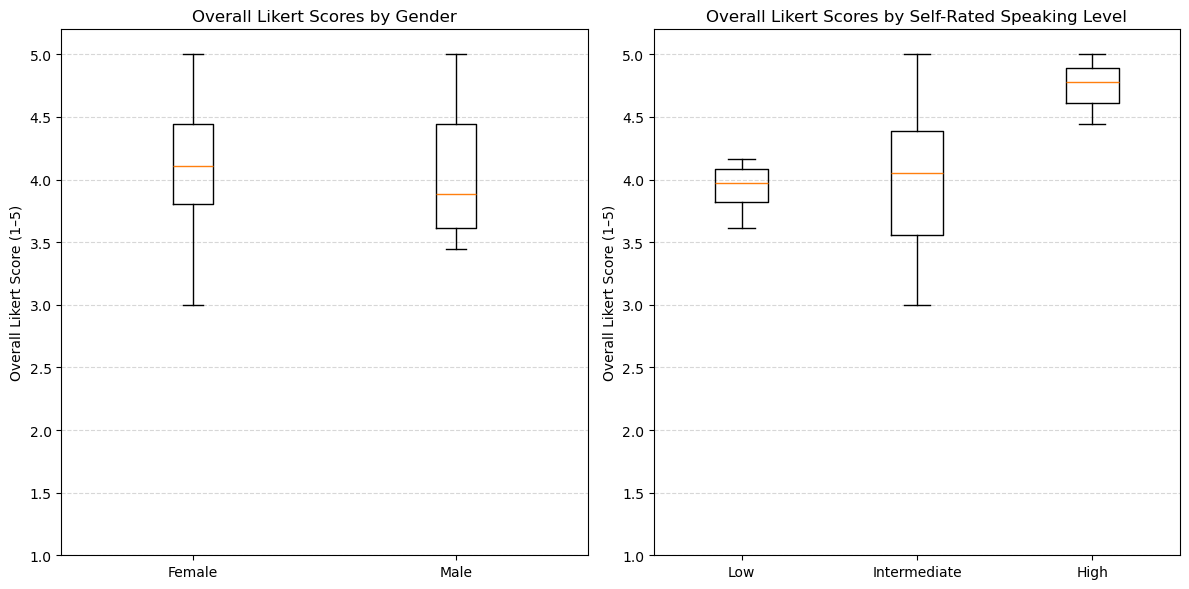

In [3]:
# corrected snippet
import matplotlib.pyplot as plt

# ============================================================
# BOXPLOTS FOR TABLE 5
# Overall Likert Scores by Gender and Speaking Level
# ============================================================

# Create figure with two boxplots
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# ------------------------------------------------------------
# 1. Boxplot by Gender
# ------------------------------------------------------------
gender_groups = [
    df.loc[df["gender"] == "Female", "mean"],
    df.loc[df["gender"] == "Male", "mean"]
]

axes[0].boxplot(
    gender_groups,
    labels=["Female", "Male"],
    patch_artist=False
)

axes[0].set_title("Overall Likert Scores by Gender")
axes[0].set_ylabel("Overall Likert Score (1–5)")
axes[0].set_ylim(1, 5.2)
axes[0].grid(axis="y", linestyle="--", alpha=0.5)


# ------------------------------------------------------------
# 2. Boxplot by Self-Rated Speaking Level
# ------------------------------------------------------------
speaking_groups = [
    df.loc[df["level"] == "Low", "mean"],
    df.loc[df["level"] == "Intermediate", "mean"],
    df.loc[df["level"] == "High", "mean"]
]

axes[1].boxplot(
    speaking_groups,
    labels=["Low", "Intermediate", "High"],
    patch_artist=False
)

axes[1].set_title("Overall Likert Scores by Self-Rated Speaking Level")
axes[1].set_ylabel("Overall Likert Score (1–5)")
axes[1].set_ylim(1, 5.2)
axes[1].grid(axis="y", linestyle="--", alpha=0.5)


# ------------------------------------------------------------
# Overall layout
# ------------------------------------------------------------
plt.tight_layout()

# Display the figure
plt.show()